In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/CIRUGÍA DE TORÁX Y CARDIOVASCULAR.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 4:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]),
                          len(answer_positions["C"]), len(answer_positions["D"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 11 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=238.4, y1=127.3
Page 1, Q1, A: Yellow pixels: 1948
Page 1, Q1, A: Total non-white pixels: 2996
Page 1, Q1, A: Yellow percentage: 65.0%


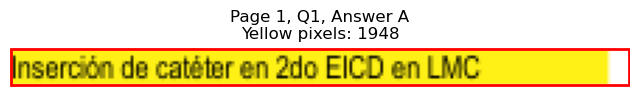

Page 1, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=200.8, y1=139.9
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 809
Page 1, Q1, B: Yellow percentage: 0.0%


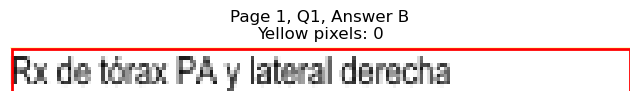

Page 1, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=426.3, y1=127.3
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 521
Page 1, Q1, C: Yellow percentage: 0.0%


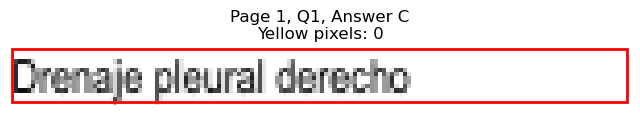

Page 1, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=434.8, y1=139.9
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 536
Page 1, Q1, D: Yellow percentage: 0.0%


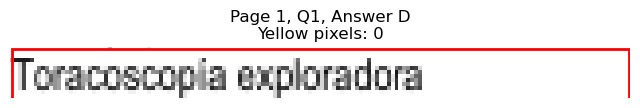


Page 1, Q1 - Selected Answer: A (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=154.1, y1=190.4
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 435
Page 1, Q2, A: Yellow percentage: 0.0%


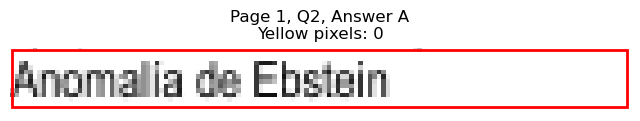

Page 1, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=186.6, y1=203.0
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 569
Page 1, Q2, B: Yellow percentage: 0.0%


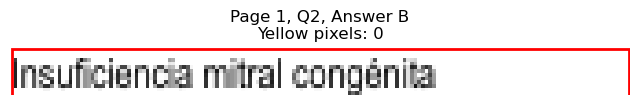

Page 1, Q2 - C: Detected box: x0=327.5, y0=177.7, x1=488.6, y1=190.4
Page 1, Q2, C: Yellow pixels: 1918
Page 1, Q2, C: Total non-white pixels: 2968
Page 1, Q2, C: Yellow percentage: 64.6%


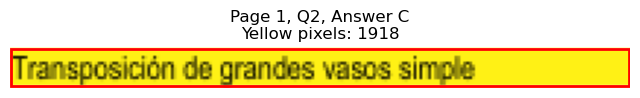

Page 1, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=407.8, y1=203.0
Page 1, Q2, D: Yellow pixels: 1
Page 1, Q2, D: Total non-white pixels: 535
Page 1, Q2, D: Yellow percentage: 0.2%


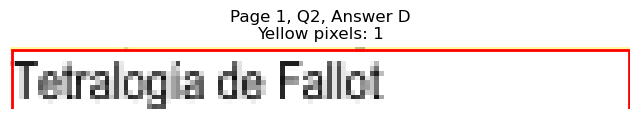


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=148.6, y1=266.1
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 392
Page 1, Q3, A: Yellow percentage: 0.0%


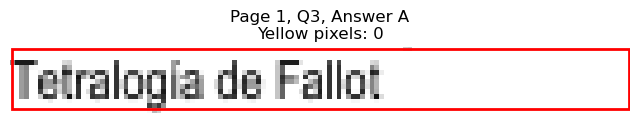

Page 1, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=176.7, y1=278.7
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 578
Page 1, Q3, B: Yellow percentage: 0.0%


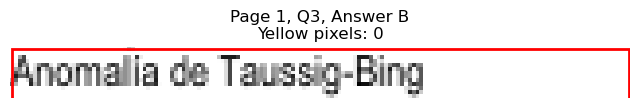

Page 1, Q3 - C: Detected box: x0=327.5, y0=253.5, x1=404.2, y1=266.1
Page 1, Q3, C: Yellow pixels: 128
Page 1, Q3, C: Total non-white pixels: 526
Page 1, Q3, C: Yellow percentage: 24.3%


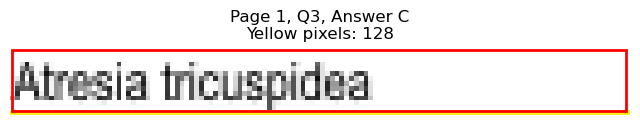

Page 1, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=490.5, y1=278.7
Page 1, Q3, D: Yellow pixels: 2147
Page 1, Q3, D: Total non-white pixels: 2782
Page 1, Q3, D: Yellow percentage: 77.2%


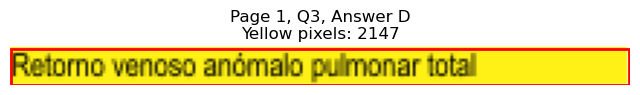


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=172.1, y1=341.9
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 532
Page 1, Q4, A: Yellow percentage: 0.0%


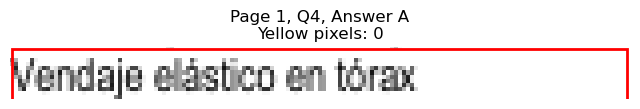

Page 1, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=211.2, y1=354.6
Page 1, Q4, B: Yellow pixels: 1945
Page 1, Q4, B: Total non-white pixels: 2716
Page 1, Q4, B: Yellow percentage: 71.6%


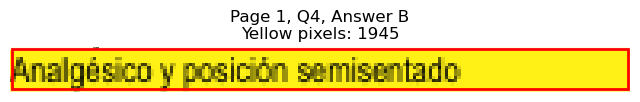

Page 1, Q4 - C: Detected box: x0=327.5, y0=329.2, x1=387.2, y1=341.9
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 313
Page 1, Q4, C: Yellow percentage: 0.0%


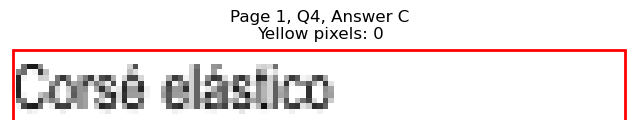

Page 1, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=395.7, y1=354.6
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 356
Page 1, Q4, D: Yellow percentage: 0.0%


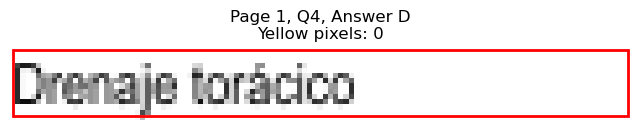


Page 1, Q4 - Selected Answer: B (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=181.7, y1=392.4
Page 1, Q5, A: Yellow pixels: 164
Page 1, Q5, A: Total non-white pixels: 748
Page 1, Q5, A: Yellow percentage: 21.9%


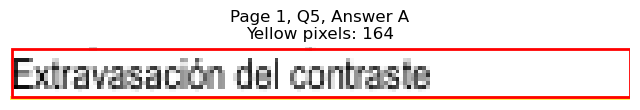

Page 1, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=159.6, y1=405.0
Page 1, Q5, B: Yellow pixels: 1475
Page 1, Q5, B: Total non-white pixels: 1846
Page 1, Q5, B: Yellow percentage: 79.9%


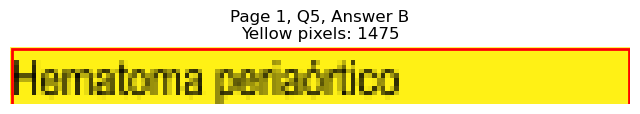

Page 1, Q5 - C: Detected box: x0=327.5, y0=379.7, x1=398.2, y1=392.4
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 358
Page 1, Q5, C: Yellow percentage: 0.0%


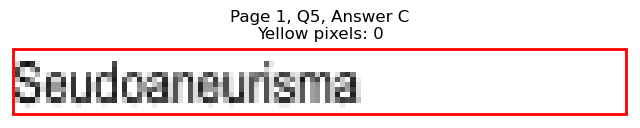

Page 1, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=409.7, y1=405.0
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 413
Page 1, Q5, D: Yellow percentage: 0.0%


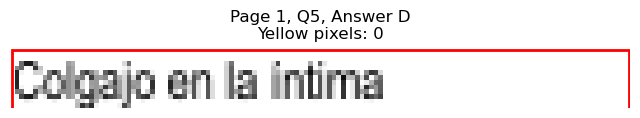


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=181.7, y1=468.1
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 582
Page 1, Q6, A: Yellow percentage: 0.0%


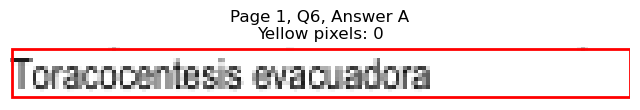

Page 1, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=171.6, y1=480.7
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 528
Page 1, Q6, B: Yellow percentage: 0.0%


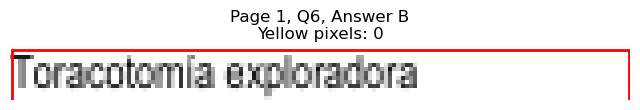

Page 1, Q6 - C: Detected box: x0=327.5, y0=455.5, x1=404.8, y1=468.1
Page 1, Q6, C: Yellow pixels: 128
Page 1, Q6, C: Total non-white pixels: 523
Page 1, Q6, C: Yellow percentage: 24.5%


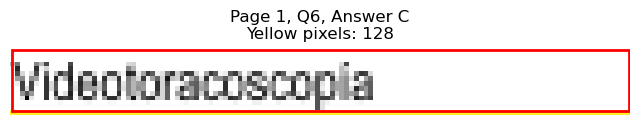

Page 1, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=391.3, y1=480.7
Page 1, Q6, D: Yellow pixels: 1233
Page 1, Q6, D: Total non-white pixels: 1495
Page 1, Q6, D: Yellow percentage: 82.5%


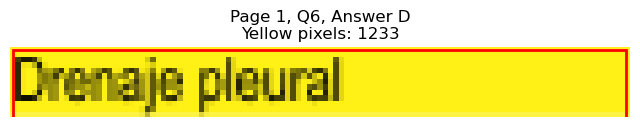


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=506.0, x1=188.2, y1=518.6
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 565
Page 1, Q7, A: Yellow percentage: 0.0%


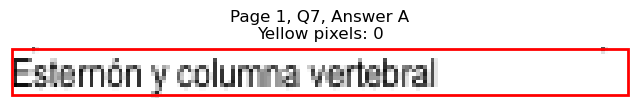

Page 1, Q7 - B: Detected box: x0=68.3, y0=518.6, x1=154.6, y1=531.2
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 411
Page 1, Q7, B: Yellow percentage: 0.0%


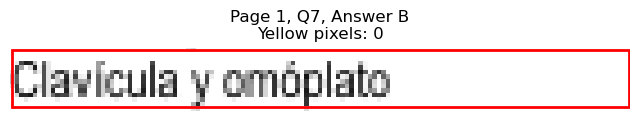

Page 1, Q7 - C: Detected box: x0=327.5, y0=506.0, x1=412.9, y1=518.6
Page 1, Q7, C: Yellow pixels: 136
Page 1, Q7, C: Total non-white pixels: 564
Page 1, Q7, C: Yellow percentage: 24.1%


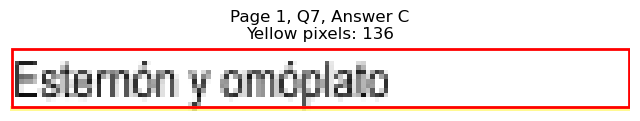

Page 1, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=450.4, y1=531.2
Page 1, Q7, D: Yellow pixels: 1769
Page 1, Q7, D: Total non-white pixels: 2436
Page 1, Q7, D: Yellow percentage: 72.6%


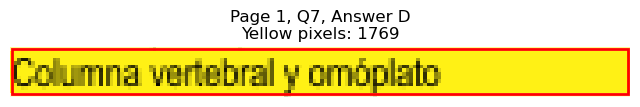


Page 1, Q7 - Selected Answer: D (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=556.5, x1=158.5, y1=569.2
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 485
Page 1, Q8, A: Yellow percentage: 0.0%


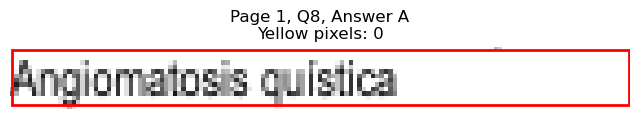

Page 1, Q8 - B: Detected box: x0=68.3, y0=569.1, x1=144.0, y1=581.8
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 395
Page 1, Q8, B: Yellow percentage: 0.0%


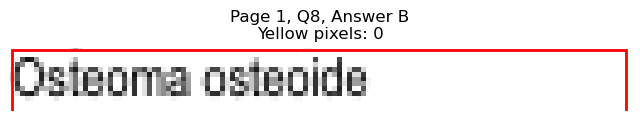

Page 1, Q8 - C: Detected box: x0=327.5, y0=556.5, x1=383.7, y1=569.2
Page 1, Q8, C: Yellow pixels: 107
Page 1, Q8, C: Total non-white pixels: 403
Page 1, Q8, C: Yellow percentage: 26.6%


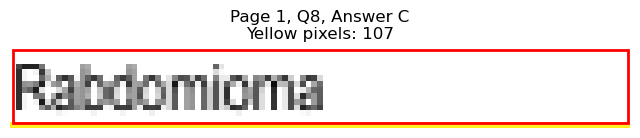

Page 1, Q8 - D: Detected box: x0=327.5, y0=569.1, x1=420.3, y1=581.8
Page 1, Q8, D: Yellow pixels: 1519
Page 1, Q8, D: Total non-white pixels: 1872
Page 1, Q8, D: Yellow percentage: 81.1%


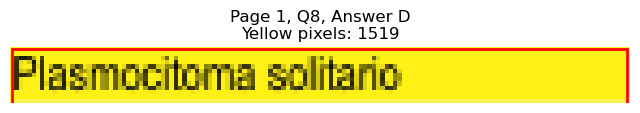


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=606.9, x1=94.3, y1=619.6
Page 1, Q9, A: Yellow pixels: 0
Page 1, Q9, A: Total non-white pixels: 130
Page 1, Q9, A: Yellow percentage: 0.0%


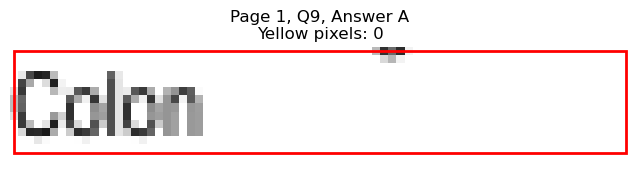

Page 1, Q9 - B: Detected box: x0=68.3, y0=619.6, x1=111.4, y1=632.3
Page 1, Q9, B: Yellow pixels: 948
Page 1, Q9, B: Total non-white pixels: 1316
Page 1, Q9, B: Yellow percentage: 72.0%


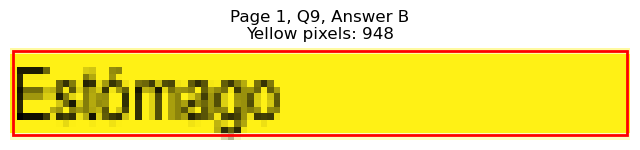

Page 1, Q9 - C: Detected box: x0=327.5, y0=606.9, x1=360.7, y1=619.6
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 153
Page 1, Q9, C: Yellow percentage: 0.0%


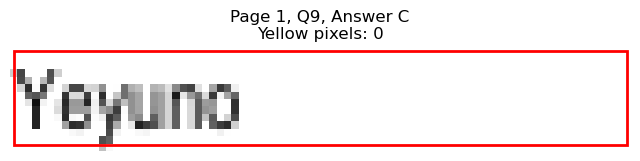

Page 1, Q9 - D: Detected box: x0=327.5, y0=619.6, x1=345.1, y1=632.3
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 79
Page 1, Q9, D: Yellow percentage: 0.0%


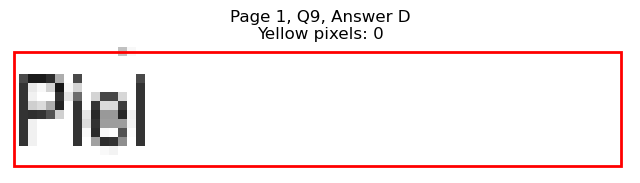


Page 1, Q9 - Selected Answer: B (based on yellow pixel count)




Page 1, Q10 - A: Detected box: x0=68.3, y0=657.5, x1=136.5, y1=670.1
Page 1, Q10, A: Yellow pixels: 1271
Page 1, Q10, A: Total non-white pixels: 1666
Page 1, Q10, A: Yellow percentage: 76.3%


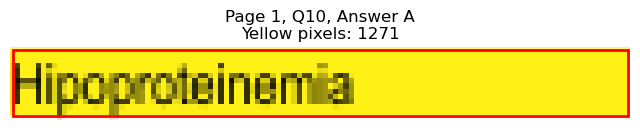

Page 1, Q10 - B: Detected box: x0=68.3, y0=670.1, x1=143.5, y1=682.7
Page 1, Q10, B: Yellow pixels: 0
Page 1, Q10, B: Total non-white pixels: 554
Page 1, Q10, B: Yellow percentage: 0.0%


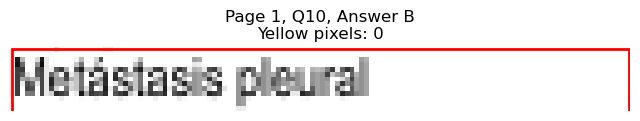

Page 1, Q10 - C: Detected box: x0=327.5, y0=657.5, x1=474.9, y1=670.1
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 778
Page 1, Q10, C: Yellow percentage: 0.0%


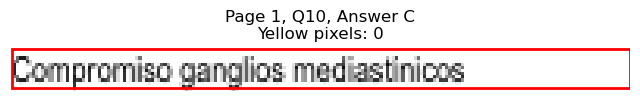

Page 1, Q10 - D: Detected box: x0=327.5, y0=670.1, x1=417.8, y1=682.7
Page 1, Q10, D: Yellow pixels: 0
Page 1, Q10, D: Total non-white pixels: 464
Page 1, Q10, D: Yellow percentage: 0.0%


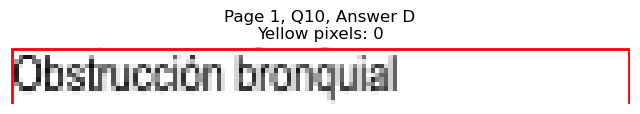


Page 1, Q10 - Selected Answer: A (based on yellow pixel count)




Page 1, Q11 - A: Detected box: x0=68.3, y0=720.6, x1=217.7, y1=733.2
Page 1, Q11, A: Yellow pixels: 0
Page 1, Q11, A: Total non-white pixels: 778
Page 1, Q11, A: Yellow percentage: 0.0%


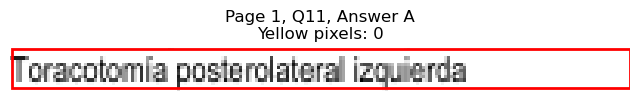

Page 1, Q11 - B: Detected box: x0=68.3, y0=733.2, x1=151.6, y1=745.8
Page 1, Q11, B: Yellow pixels: 0
Page 1, Q11, B: Total non-white pixels: 426
Page 1, Q11, B: Yellow percentage: 0.0%


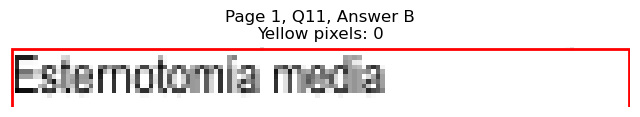

Page 1, Q11 - C: Detected box: x0=327.5, y0=720.6, x1=448.9, y1=733.2
Page 1, Q11, C: Yellow pixels: 172
Page 1, Q11, C: Total non-white pixels: 770
Page 1, Q11, C: Yellow percentage: 22.3%


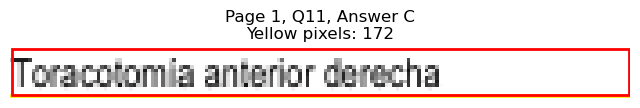

Page 1, Q11 - D: Detected box: x0=327.5, y0=733.2, x1=473.0, y1=745.8
Page 1, Q11, D: Yellow pixels: 1992
Page 1, Q11, D: Total non-white pixels: 2561
Page 1, Q11, D: Yellow percentage: 77.8%


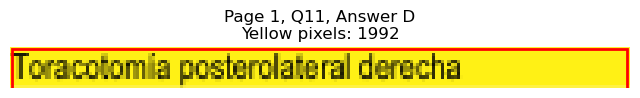


Page 1, Q11 - Selected Answer: D (based on yellow pixel count)





Page 2: Found 12 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=140.5, y1=102.1
Page 2, Q1, A: Yellow pixels: 123
Page 2, Q1, A: Total non-white pixels: 470
Page 2, Q1, A: Yellow percentage: 26.2%


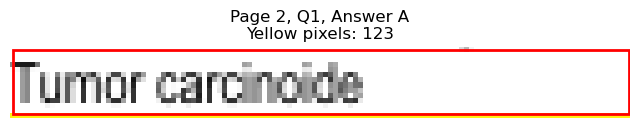

Page 2, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=185.2, y1=114.7
Page 2, Q1, B: Yellow pixels: 1694
Page 2, Q1, B: Total non-white pixels: 2184
Page 2, Q1, B: Yellow percentage: 77.6%


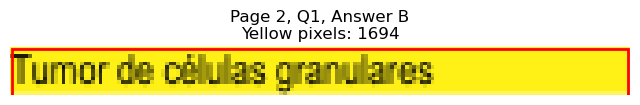

Page 2, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=425.8, y1=102.1
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 497
Page 2, Q1, C: Yellow percentage: 0.0%


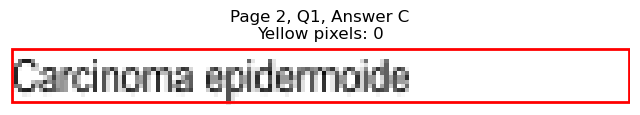

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=452.0, y1=114.7
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 620
Page 2, Q1, D: Yellow percentage: 0.0%


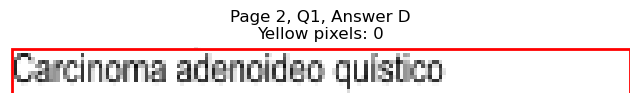


Page 2, Q1 - Selected Answer: B (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=85.3, y1=165.2
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 76
Page 2, Q2, A: Yellow percentage: 0.0%


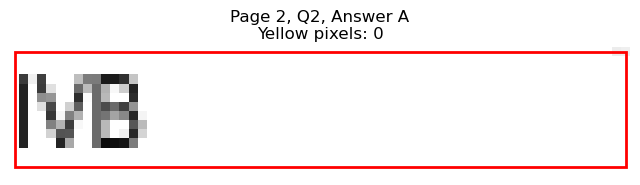

Page 2, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=84.4, y1=177.8
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 70
Page 2, Q2, B: Yellow percentage: 0.0%


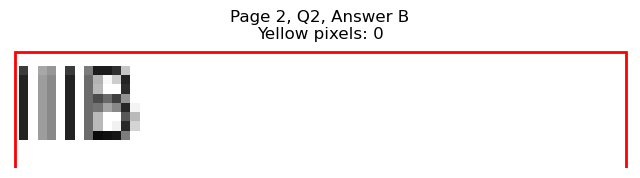

Page 2, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=344.6, y1=165.2
Page 2, Q2, C: Yellow pixels: 816
Page 2, Q2, C: Total non-white pixels: 952
Page 2, Q2, C: Yellow percentage: 85.7%


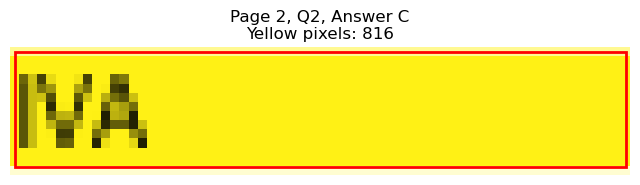

Page 2, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=344.1, y1=177.8
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 149
Page 2, Q2, D: Yellow percentage: 0.0%


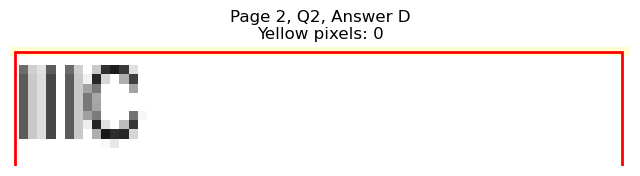


Page 2, Q2 - Selected Answer: C (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=129.5, y1=228.3
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 317
Page 2, Q3, A: Yellow percentage: 0.0%


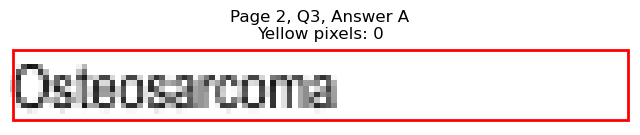

Page 2, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=112.9, y1=240.9
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 213
Page 2, Q3, B: Yellow percentage: 0.0%


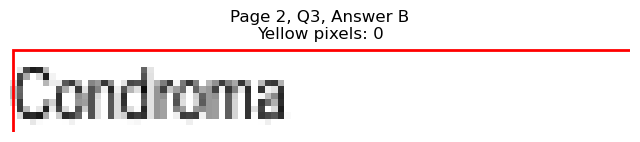

Page 2, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=435.9, y1=228.3
Page 2, Q3, C: Yellow pixels: 159
Page 2, Q3, C: Total non-white pixels: 727
Page 2, Q3, C: Yellow percentage: 21.9%


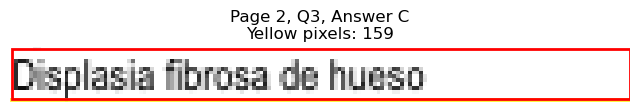

Page 2, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=394.3, y1=240.9
Page 2, Q3, D: Yellow pixels: 1270
Page 2, Q3, D: Total non-white pixels: 1534
Page 2, Q3, D: Yellow percentage: 82.8%


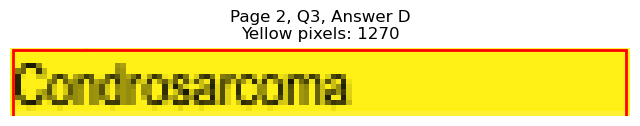


Page 2, Q3 - Selected Answer: D (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=182.7, y1=291.5
Page 2, Q4, A: Yellow pixels: 165
Page 2, Q4, A: Total non-white pixels: 718
Page 2, Q4, A: Yellow percentage: 23.0%


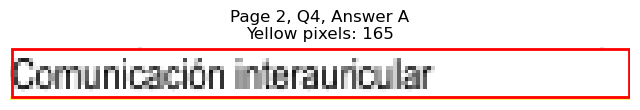

Page 2, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=196.7, y1=304.1
Page 2, Q4, B: Yellow pixels: 1847
Page 2, Q4, B: Total non-white pixels: 2506
Page 2, Q4, B: Yellow percentage: 73.7%


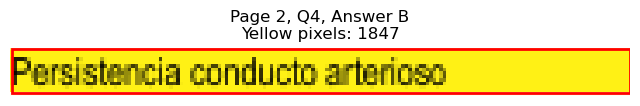

Page 2, Q4 - C: Detected box: x0=327.5, y0=278.8, x1=448.9, y1=291.5
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 602
Page 2, Q4, C: Yellow percentage: 0.0%


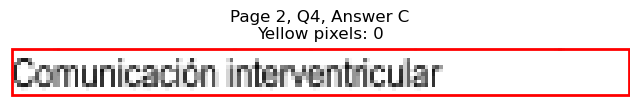

Page 2, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=409.3, y1=304.1
Page 2, Q4, D: Yellow pixels: 0
Page 2, Q4, D: Total non-white pixels: 415
Page 2, Q4, D: Yellow percentage: 0.0%


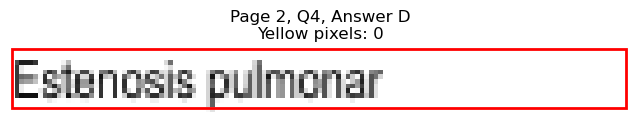


Page 2, Q4 - Selected Answer: B (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=329.2, x1=163.6, y1=341.9
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 481
Page 2, Q5, A: Yellow percentage: 0.0%


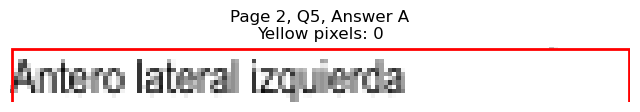

Page 2, Q5 - B: Detected box: x0=68.3, y0=341.9, x1=132.5, y1=354.6
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 336
Page 2, Q5, B: Yellow percentage: 0.0%


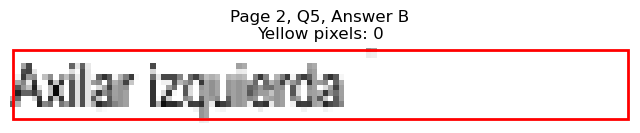

Page 2, Q5 - C: Detected box: x0=327.5, y0=329.2, x1=427.4, y1=341.9
Page 2, Q5, C: Yellow pixels: 1583
Page 2, Q5, C: Total non-white pixels: 1963
Page 2, Q5, C: Yellow percentage: 80.6%


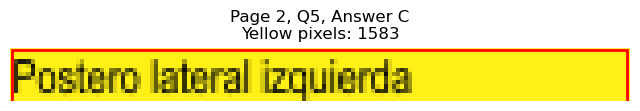

Page 2, Q5 - D: Detected box: x0=327.5, y0=341.9, x1=472.5, y1=354.6
Page 2, Q5, D: Yellow pixels: 195
Page 2, Q5, D: Total non-white pixels: 933
Page 2, Q5, D: Yellow percentage: 20.9%


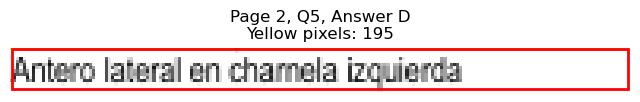


Page 2, Q5 - Selected Answer: C (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=392.3, x1=127.5, y1=405.0
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 393
Page 2, Q6, A: Yellow percentage: 0.0%


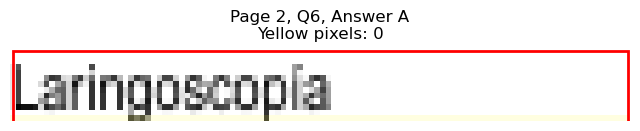

Page 2, Q6 - B: Detected box: x0=68.3, y0=404.9, x1=145.6, y1=417.6
Page 2, Q6, B: Yellow pixels: 1353
Page 2, Q6, B: Total non-white pixels: 1792
Page 2, Q6, B: Yellow percentage: 75.5%


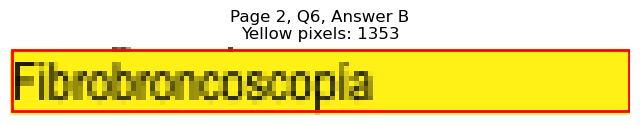

Page 2, Q6 - C: Detected box: x0=327.5, y0=392.3, x1=362.1, y1=405.0
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 163
Page 2, Q6, C: Yellow percentage: 0.0%


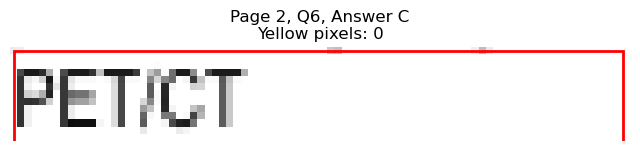

Page 2, Q6 - D: Detected box: x0=327.5, y0=404.9, x1=377.7, y1=417.6
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 246
Page 2, Q6, D: Yellow percentage: 0.0%


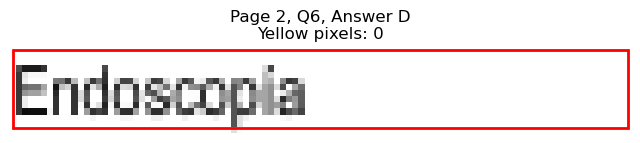


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=442.8, x1=138.5, y1=455.5
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 350
Page 2, Q7, A: Yellow percentage: 0.0%


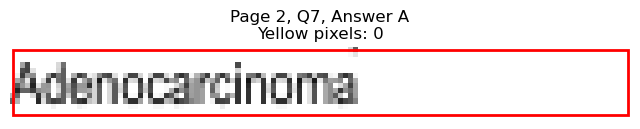

Page 2, Q7 - B: Detected box: x0=68.3, y0=455.5, x1=257.8, y1=468.1
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 918
Page 2, Q7, B: Yellow percentage: 0.0%


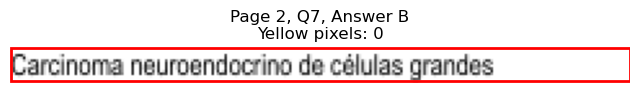

Page 2, Q7 - C: Detected box: x0=327.5, y0=89.4, x1=425.8, y1=102.1
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 497
Page 2, Q7, C: Yellow percentage: 0.0%


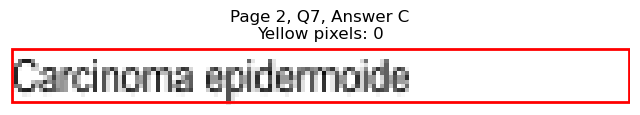

Page 2, Q7 - D: Detected box: x0=327.5, y0=455.5, x1=458.9, y1=468.1
Page 2, Q7, D: Yellow pixels: 1873
Page 2, Q7, D: Total non-white pixels: 2548
Page 2, Q7, D: Yellow percentage: 73.5%


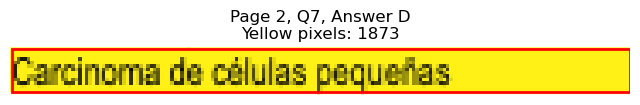


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=493.4, x1=167.1, y1=506.0
Page 2, Q8, A: Yellow pixels: 1596
Page 2, Q8, A: Total non-white pixels: 1956
Page 2, Q8, A: Yellow percentage: 81.6%


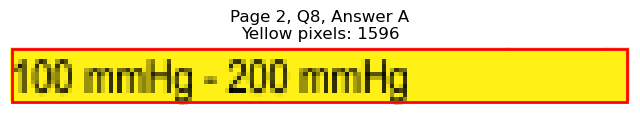

Page 2, Q8 - B: Detected box: x0=68.3, y0=506.0, x1=167.1, y1=518.6
Page 2, Q8, B: Yellow pixels: 142
Page 2, Q8, B: Total non-white pixels: 597
Page 2, Q8, B: Yellow percentage: 23.8%


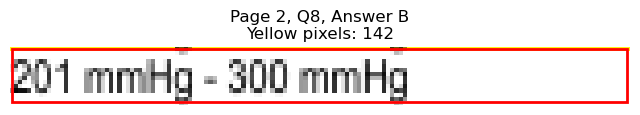

Page 2, Q8 - C: Detected box: x0=327.5, y0=493.4, x1=382.7, y1=506.0
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 267
Page 2, Q8, C: Yellow percentage: 0.0%


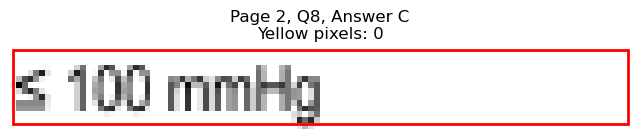

Page 2, Q8 - D: Detected box: x0=327.5, y0=506.0, x1=428.3, y1=518.6
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 476
Page 2, Q8, D: Yellow percentage: 0.0%


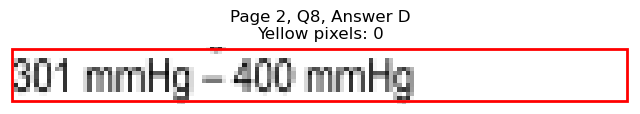


Page 2, Q8 - Selected Answer: A (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=543.8, x1=145.6, y1=556.4
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 384
Page 2, Q9, A: Yellow percentage: 0.0%


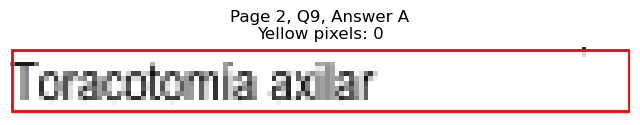

Page 2, Q9 - B: Detected box: x0=68.3, y0=556.5, x1=178.6, y1=569.2
Page 2, Q9, B: Yellow pixels: 0
Page 2, Q9, B: Total non-white pixels: 562
Page 2, Q9, B: Yellow percentage: 0.0%


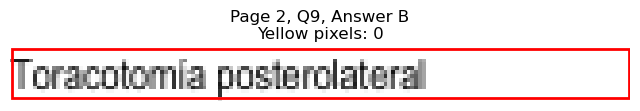

Page 2, Q9 - C: Detected box: x0=327.5, y0=543.8, x1=410.8, y1=556.4
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 427
Page 2, Q9, C: Yellow percentage: 0.0%


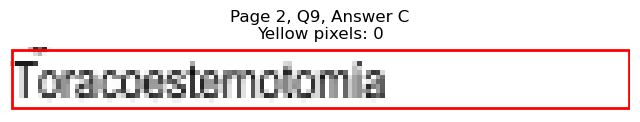

Page 2, Q9 - D: Detected box: x0=327.5, y0=556.5, x1=413.8, y1=569.2
Page 2, Q9, D: Yellow pixels: 1442
Page 2, Q9, D: Total non-white pixels: 1918
Page 2, Q9, D: Yellow percentage: 75.2%


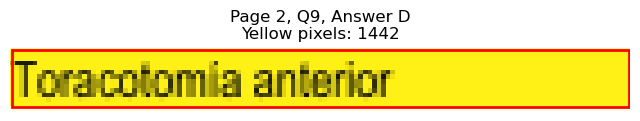


Page 2, Q9 - Selected Answer: D (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=68.3, y0=606.9, x1=150.0, y1=619.6
Page 2, Q10, A: Yellow pixels: 1427
Page 2, Q10, A: Total non-white pixels: 1862
Page 2, Q10, A: Yellow percentage: 76.6%


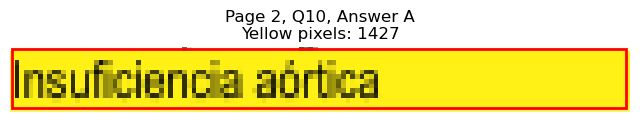

Page 2, Q10 - B: Detected box: x0=68.3, y0=619.6, x1=139.6, y1=632.3
Page 2, Q10, B: Yellow pixels: 122
Page 2, Q10, B: Total non-white pixels: 492
Page 2, Q10, B: Yellow percentage: 24.8%


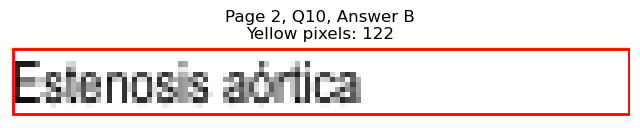

Page 2, Q10 - C: Detected box: x0=327.5, y0=606.9, x1=509.7, y1=619.6
Page 2, Q10, C: Yellow pixels: 0
Page 2, Q10, C: Total non-white pixels: 969
Page 2, Q10, C: Yellow percentage: 0.0%


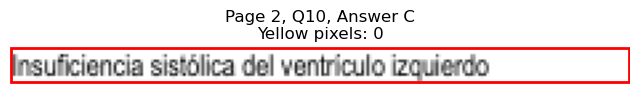

Page 2, Q10 - D: Detected box: x0=327.5, y0=619.6, x1=436.4, y1=632.3
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 597
Page 2, Q10, D: Yellow percentage: 0.0%


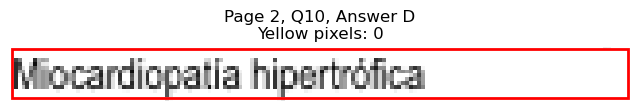


Page 2, Q10 - Selected Answer: A (based on yellow pixel count)




Page 2, Q11 - A: Detected box: x0=68.3, y0=657.5, x1=127.0, y1=670.1
Page 2, Q11, A: Yellow pixels: 109
Page 2, Q11, A: Total non-white pixels: 405
Page 2, Q11, A: Yellow percentage: 26.9%


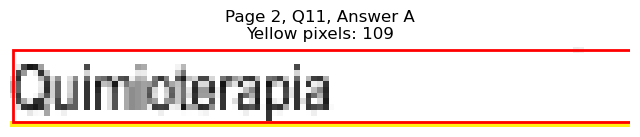

Page 2, Q11 - B: Detected box: x0=68.3, y0=670.1, x1=121.9, y1=682.7
Page 2, Q11, B: Yellow pixels: 1152
Page 2, Q11, B: Total non-white pixels: 1352
Page 2, Q11, B: Yellow percentage: 85.2%


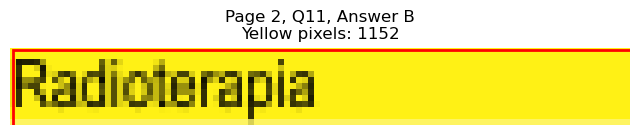

Page 2, Q11 - C: Detected box: x0=327.5, y0=657.5, x1=359.1, y1=670.1
Page 2, Q11, C: Yellow pixels: 0
Page 2, Q11, C: Total non-white pixels: 171
Page 2, Q11, C: Yellow percentage: 0.0%


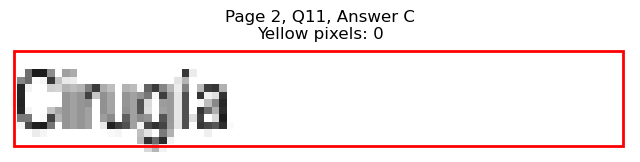

Page 2, Q11 - D: Detected box: x0=327.5, y0=670.1, x1=422.8, y1=682.7
Page 2, Q11, D: Yellow pixels: 0
Page 2, Q11, D: Total non-white pixels: 495
Page 2, Q11, D: Yellow percentage: 0.0%


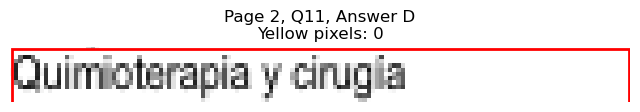


Page 2, Q11 - Selected Answer: B (based on yellow pixel count)




Page 2, Q12 - A: Detected box: x0=68.3, y0=708.0, x1=148.1, y1=720.6
Page 2, Q12, A: Yellow pixels: 131
Page 2, Q12, A: Total non-white pixels: 514
Page 2, Q12, A: Yellow percentage: 25.5%


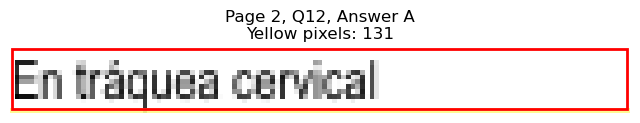

Page 2, Q12 - B: Detected box: x0=68.3, y0=720.6, x1=155.5, y1=733.2
Page 2, Q12, B: Yellow pixels: 1488
Page 2, Q12, B: Total non-white pixels: 1932
Page 2, Q12, B: Yellow percentage: 77.0%


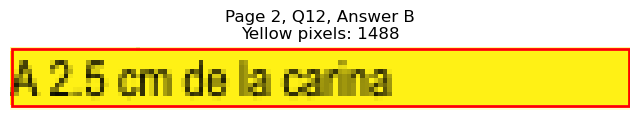

Page 2, Q12 - C: Detected box: x0=327.5, y0=708.0, x1=518.7, y1=720.6
Page 2, Q12, C: Yellow pixels: 0
Page 2, Q12, C: Total non-white pixels: 903
Page 2, Q12, C: Yellow percentage: 0.0%


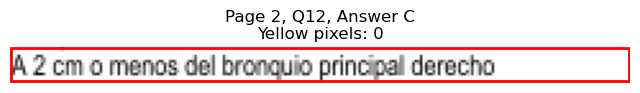

Page 2, Q12 - D: Detected box: x0=327.5, y0=720.6, x1=520.2, y1=733.2
Page 2, Q12, D: Yellow pixels: 0
Page 2, Q12, D: Total non-white pixels: 936
Page 2, Q12, D: Yellow percentage: 0.0%


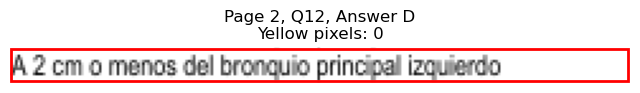


Page 2, Q12 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 11 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=162.6, y1=139.9
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 478
Page 3, Q1, A: Yellow percentage: 0.0%


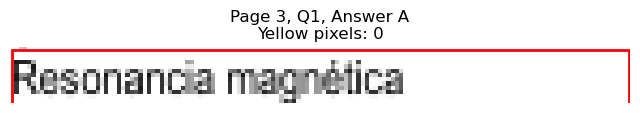

Page 3, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=118.5, y1=152.6
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 246
Page 3, Q1, B: Yellow percentage: 0.0%


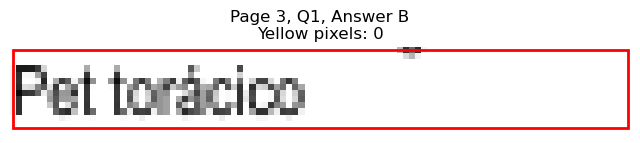

Page 3, Q1 - C: Detected box: x0=327.5, y0=127.2, x1=393.3, y1=139.9
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 347
Page 3, Q1, C: Yellow percentage: 0.0%


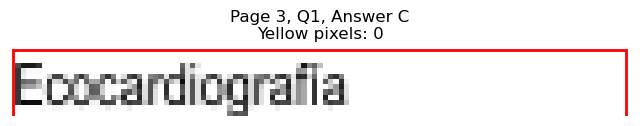

Page 3, Q1 - D: Detected box: x0=327.5, y0=139.9, x1=437.8, y1=152.6
Page 3, Q1, D: Yellow pixels: 1673
Page 3, Q1, D: Total non-white pixels: 2254
Page 3, Q1, D: Yellow percentage: 74.2%


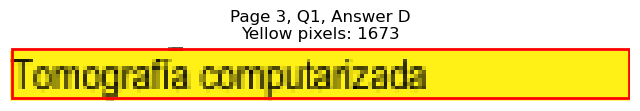


Page 3, Q1 - Selected Answer: D (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=109.5, y1=190.4
Page 3, Q2, A: Yellow pixels: 92
Page 3, Q2, A: Total non-white pixels: 294
Page 3, Q2, A: Yellow percentage: 31.3%


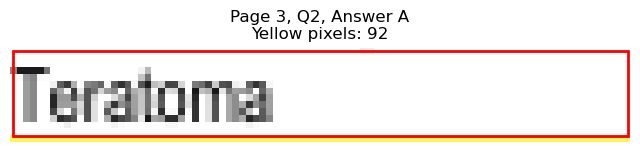

Page 3, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=103.3, y1=203.0
Page 3, Q2, B: Yellow pixels: 996
Page 3, Q2, B: Total non-white pixels: 1118
Page 3, Q2, B: Yellow percentage: 89.1%


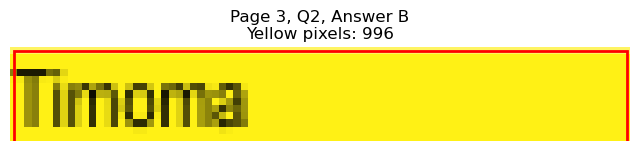

Page 3, Q2 - C: Detected box: x0=327.5, y0=177.7, x1=445.9, y1=190.4
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 599
Page 3, Q2, C: Yellow percentage: 0.0%


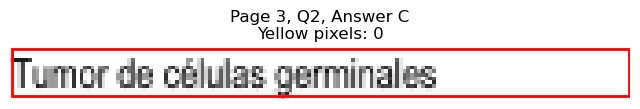

Page 3, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=373.1, y1=203.0
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 234
Page 3, Q2, D: Yellow percentage: 0.0%


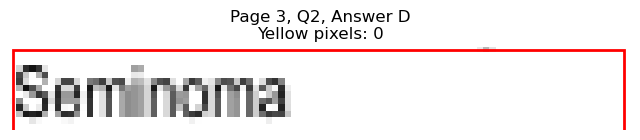


Page 3, Q2 - Selected Answer: B (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=92.4, y1=253.5
Page 3, Q3, A: Yellow pixels: 75
Page 3, Q3, A: Total non-white pixels: 180
Page 3, Q3, A: Yellow percentage: 41.7%


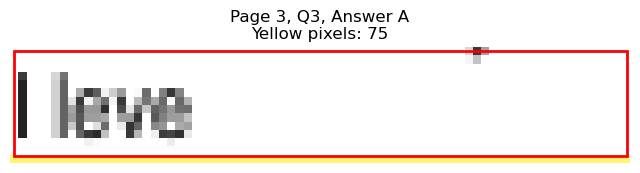

Page 3, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=118.9, y1=266.1
Page 3, Q3, B: Yellow pixels: 1142
Page 3, Q3, B: Total non-white pixels: 1414
Page 3, Q3, B: Yellow percentage: 80.8%


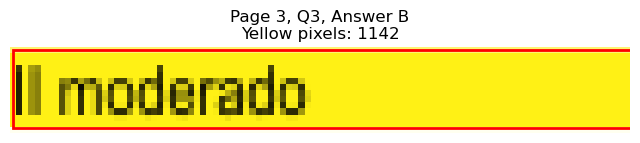

Page 3, Q3 - C: Detected box: x0=327.5, y0=240.9, x1=362.7, y1=253.5
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 172
Page 3, Q3, C: Yellow percentage: 0.0%


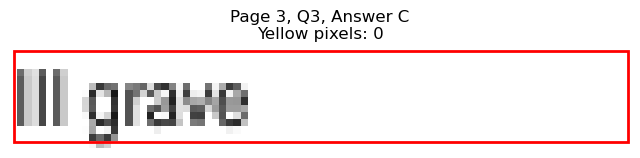

Page 3, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=383.2, y1=266.1
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 261
Page 3, Q3, D: Yellow percentage: 0.0%


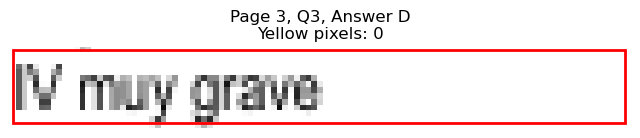


Page 3, Q3 - Selected Answer: B (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=210.2, y1=316.7
Page 3, Q4, A: Yellow pixels: 1
Page 3, Q4, A: Total non-white pixels: 924
Page 3, Q4, A: Yellow percentage: 0.1%


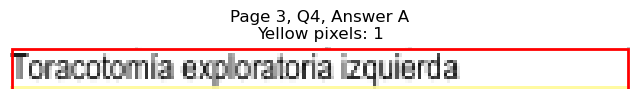

Page 3, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=262.5, y1=329.3
Page 3, Q4, B: Yellow pixels: 1765
Page 3, Q4, B: Total non-white pixels: 2996
Page 3, Q4, B: Yellow percentage: 58.9%


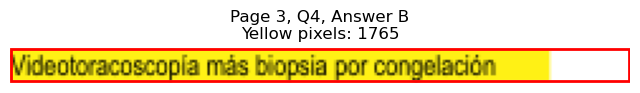

Page 3, Q4 - C: Detected box: x0=327.5, y0=304.0, x1=457.5, y1=316.7
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 698
Page 3, Q4, C: Yellow percentage: 0.0%


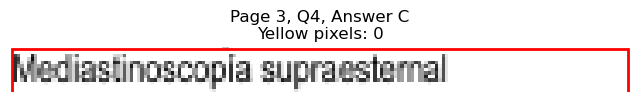

Page 3, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=404.8, y1=329.3
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 404
Page 3, Q4, D: Yellow percentage: 0.0%


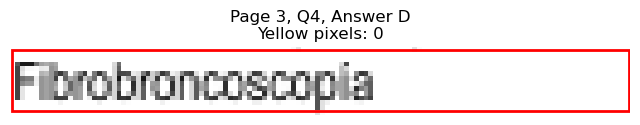


Page 3, Q4 - Selected Answer: B (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=166.6, y1=367.2
Page 3, Q5, A: Yellow pixels: 1566
Page 3, Q5, A: Total non-white pixels: 2086
Page 3, Q5, A: Yellow percentage: 75.1%


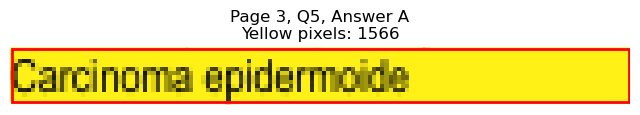

Page 3, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=192.7, y1=379.8
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 766
Page 3, Q5, B: Yellow percentage: 0.0%


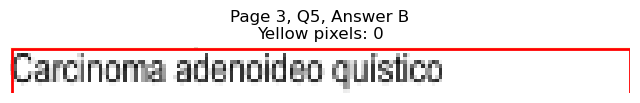

Page 3, Q5 - C: Detected box: x0=327.5, y0=354.5, x1=366.2, y1=367.2
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 190
Page 3, Q5, C: Yellow percentage: 0.0%


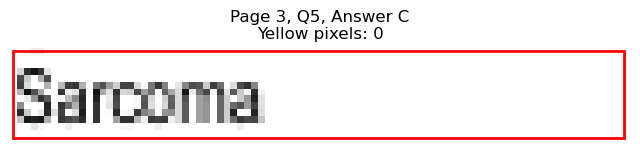

Page 3, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=399.8, y1=379.8
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 347
Page 3, Q5, D: Yellow percentage: 0.0%


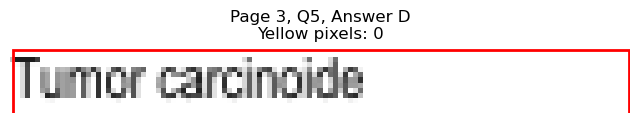


Page 3, Q5 - Selected Answer: A (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=417.6, x1=125.5, y1=430.3
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 284
Page 3, Q6, A: Yellow percentage: 0.0%


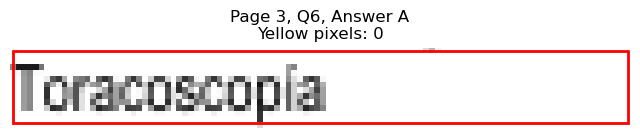

Page 3, Q6 - B: Detected box: x0=68.3, y0=430.2, x1=141.0, y1=442.9
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 417
Page 3, Q6, B: Yellow percentage: 0.0%


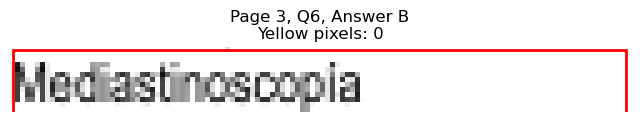

Page 3, Q6 - C: Detected box: x0=327.5, y0=417.6, x1=404.8, y1=430.3
Page 3, Q6, C: Yellow pixels: 1216
Page 3, Q6, C: Total non-white pixels: 1792
Page 3, Q6, C: Yellow percentage: 67.9%


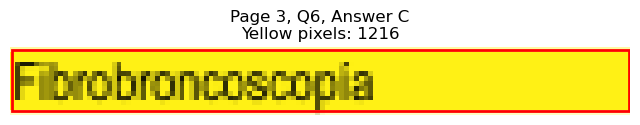

Page 3, Q6 - D: Detected box: x0=327.5, y0=430.2, x1=386.7, y1=442.9
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 383
Page 3, Q6, D: Yellow percentage: 0.0%


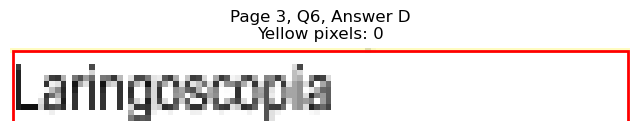


Page 3, Q6 - Selected Answer: C (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=468.1, x1=242.3, y1=480.7
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 855
Page 3, Q7, A: Yellow percentage: 0.0%


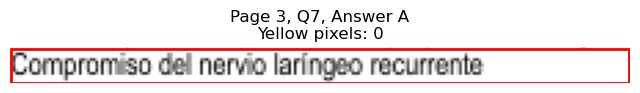

Page 3, Q7 - B: Detected box: x0=68.3, y0=480.8, x1=164.5, y1=493.4
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 505
Page 3, Q7, B: Yellow percentage: 0.0%


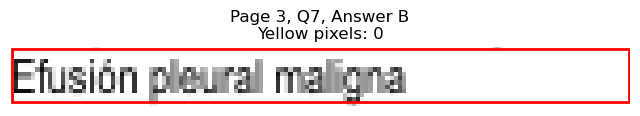

Page 3, Q7 - C: Detected box: x0=327.5, y0=468.1, x1=431.3, y1=480.7
Page 3, Q7, C: Yellow pixels: 1615
Page 3, Q7, C: Total non-white pixels: 2015
Page 3, Q7, C: Yellow percentage: 80.1%


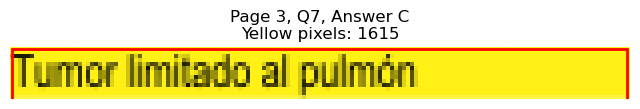

Page 3, Q7 - D: Detected box: x0=327.5, y0=480.8, x1=418.9, y1=493.4
Page 3, Q7, D: Yellow pixels: 142
Page 3, Q7, D: Total non-white pixels: 617
Page 3, Q7, D: Yellow percentage: 23.0%


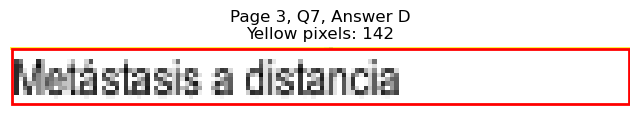


Page 3, Q7 - Selected Answer: C (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=531.2, x1=166.1, y1=543.8
Page 3, Q8, A: Yellow pixels: 1569
Page 3, Q8, A: Total non-white pixels: 1937
Page 3, Q8, A: Yellow percentage: 81.0%


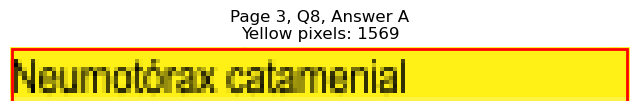

Page 3, Q8 - B: Detected box: x0=68.3, y0=543.8, x1=209.3, y1=556.4
Page 3, Q8, B: Yellow pixels: 192
Page 3, Q8, B: Total non-white pixels: 908
Page 3, Q8, B: Yellow percentage: 21.1%


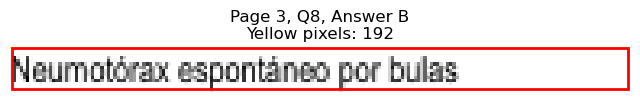

Page 3, Q8 - C: Detected box: x0=327.5, y0=531.2, x1=423.8, y1=543.8
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 479
Page 3, Q8, C: Yellow percentage: 0.0%


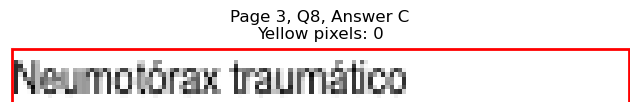

Page 3, Q8 - D: Detected box: x0=327.5, y0=543.8, x1=428.8, y1=556.4
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 537
Page 3, Q8, D: Yellow percentage: 0.0%


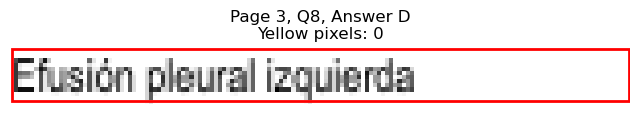


Page 3, Q8 - Selected Answer: A (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=594.3, x1=77.3, y1=607.0
Page 3, Q9, A: Yellow pixels: 0
Page 3, Q9, A: Total non-white pixels: 39
Page 3, Q9, A: Yellow percentage: 0.0%


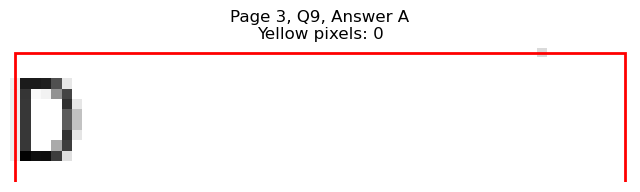

Page 3, Q9 - B: Detected box: x0=68.3, y0=606.9, x1=76.8, y1=619.6
Page 3, Q9, B: Yellow pixels: 0
Page 3, Q9, B: Total non-white pixels: 41
Page 3, Q9, B: Yellow percentage: 0.0%


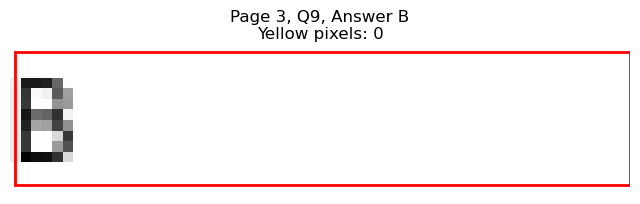

Page 3, Q9 - C: Detected box: x0=315.4, y0=594.3, x1=324.4, y1=607.0
Page 3, Q9, C: Yellow pixels: 729
Page 3, Q9, C: Total non-white pixels: 780
Page 3, Q9, C: Yellow percentage: 93.5%


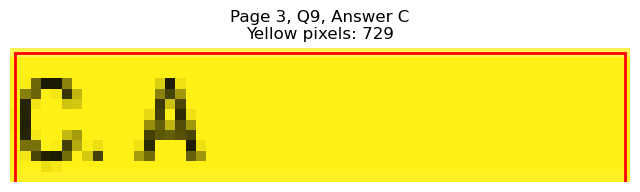

Page 3, Q9 - D: Detected box: x0=327.5, y0=606.9, x1=336.5, y1=619.6
Page 3, Q9, D: Yellow pixels: 60
Page 3, Q9, D: Total non-white pixels: 93
Page 3, Q9, D: Yellow percentage: 64.5%


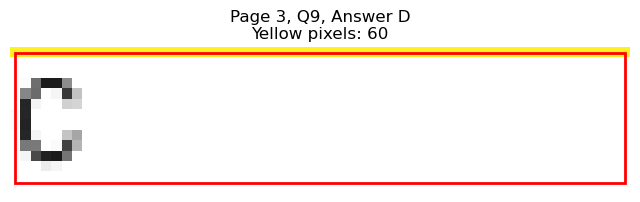


Page 3, Q9 - Selected Answer: C (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=68.3, y0=644.9, x1=108.4, y1=657.5
Page 3, Q10, A: Yellow pixels: 91
Page 3, Q10, A: Total non-white pixels: 282
Page 3, Q10, A: Yellow percentage: 32.3%


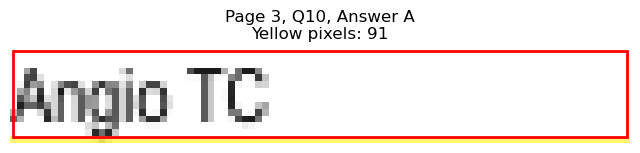

Page 3, Q10 - B: Detected box: x0=68.3, y0=657.5, x1=134.1, y1=670.1
Page 3, Q10, B: Yellow pixels: 1279
Page 3, Q10, B: Total non-white pixels: 1638
Page 3, Q10, B: Yellow percentage: 78.1%


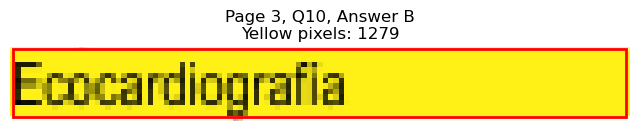

Page 3, Q10 - C: Detected box: x0=327.5, y0=644.9, x1=376.1, y1=657.5
Page 3, Q10, C: Yellow pixels: 0
Page 3, Q10, C: Total non-white pixels: 245
Page 3, Q10, C: Yellow percentage: 0.0%


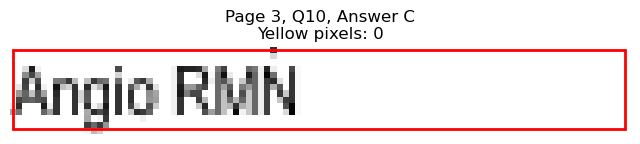

Page 3, Q10 - D: Detected box: x0=327.5, y0=657.5, x1=411.8, y1=670.1
Page 3, Q10, D: Yellow pixels: 0
Page 3, Q10, D: Total non-white pixels: 440
Page 3, Q10, D: Yellow percentage: 0.0%


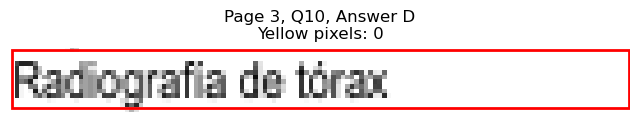


Page 3, Q10 - Selected Answer: B (based on yellow pixel count)




Page 3, Q11 - A: Detected box: x0=68.3, y0=695.4, x1=327.5, y1=708.0
Page 3, Q11, A: Yellow pixels: 3046
Page 3, Q11, A: Total non-white pixels: 4038
Page 3, Q11, A: Yellow percentage: 75.4%


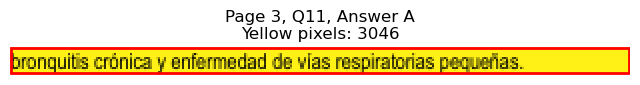

Page 3, Q11 - B: Detected box: x0=68.3, y0=708.0, x1=203.2, y1=720.6
Page 3, Q11, B: Yellow pixels: 181
Page 3, Q11, B: Total non-white pixels: 851
Page 3, Q11, B: Yellow percentage: 21.3%


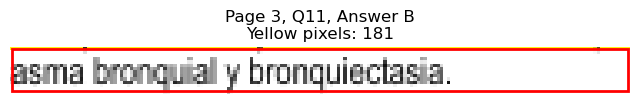

Page 3, Q11 - C: Detected box: x0=68.8, y0=720.6, x1=319.1, y1=733.2
Page 3, Q11, C: Yellow pixels: 0
Page 3, Q11, C: Total non-white pixels: 1272
Page 3, Q11, C: Yellow percentage: 0.0%


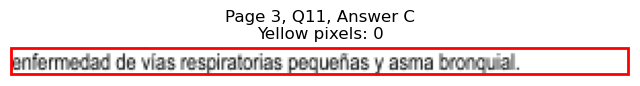

Page 3, Q11 - D: Detected box: x0=68.8, y0=733.2, x1=192.1, y1=745.8
Page 3, Q11, D: Yellow pixels: 0
Page 3, Q11, D: Total non-white pixels: 594
Page 3, Q11, D: Yellow percentage: 0.0%


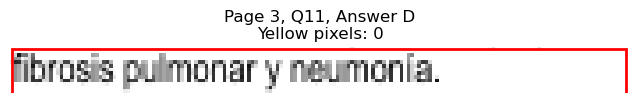


Page 3, Q11 - Selected Answer: A (based on yellow pixel count)





Page 4: Found 12 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=246.3, y1=102.1
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 867
Page 4, Q1, A: Yellow percentage: 0.0%


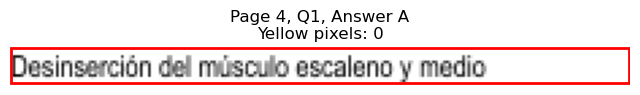

Page 4, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=200.2, y1=114.7
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 626
Page 4, Q1, B: Yellow percentage: 0.0%


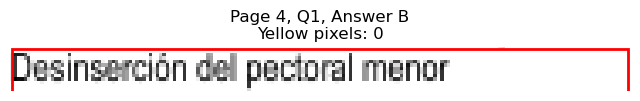

Page 4, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=457.5, y1=102.1
Page 4, Q1, C: Yellow pixels: 181
Page 4, Q1, C: Total non-white pixels: 845
Page 4, Q1, C: Yellow percentage: 21.4%


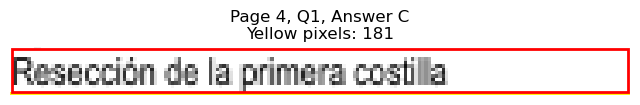

Page 4, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=412.3, y1=114.7
Page 4, Q1, D: Yellow pixels: 1415
Page 4, Q1, D: Total non-white pixels: 1768
Page 4, Q1, D: Yellow percentage: 80.0%


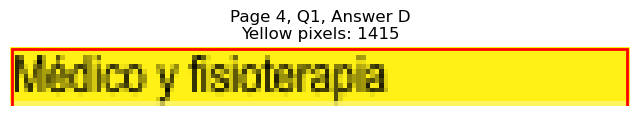


Page 4, Q1 - Selected Answer: D (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=139.9, x1=147.5, y1=152.6
Page 4, Q2, A: Yellow pixels: 1360
Page 4, Q2, A: Total non-white pixels: 1820
Page 4, Q2, A: Yellow percentage: 74.7%


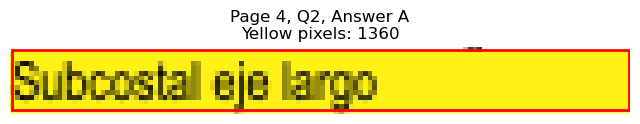

Page 4, Q2 - B: Detected box: x0=68.3, y0=152.5, x1=95.4, y1=165.2
Page 4, Q2, B: Yellow pixels: 76
Page 4, Q2, B: Total non-white pixels: 223
Page 4, Q2, B: Yellow percentage: 34.1%


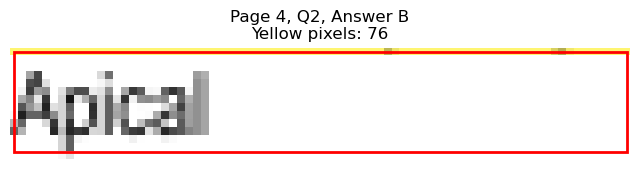

Page 4, Q2 - C: Detected box: x0=327.5, y0=139.9, x1=381.2, y1=152.6
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 276
Page 4, Q2, C: Yellow percentage: 0.0%


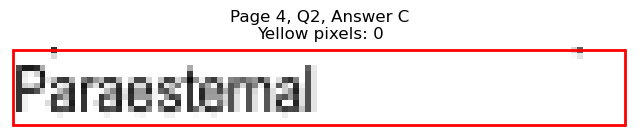

Page 4, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=386.2, y1=165.2
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 289
Page 4, Q2, D: Yellow percentage: 0.0%


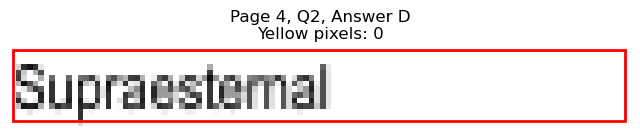


Page 4, Q2 - Selected Answer: A (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=190.3, x1=146.5, y1=203.0
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 522
Page 4, Q3, A: Yellow percentage: 0.0%


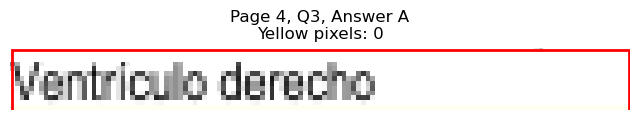

Page 4, Q3 - B: Detected box: x0=68.3, y0=202.9, x1=134.5, y1=215.6
Page 4, Q3, B: Yellow pixels: 1287
Page 4, Q3, B: Total non-white pixels: 1638
Page 4, Q3, B: Yellow percentage: 78.6%


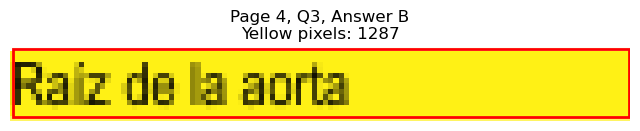

Page 4, Q3 - C: Detected box: x0=327.5, y0=190.3, x1=396.8, y1=203.0
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 343
Page 4, Q3, C: Yellow percentage: 0.0%


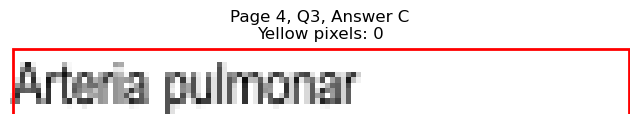

Page 4, Q3 - D: Detected box: x0=327.5, y0=202.9, x1=402.8, y1=215.6
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 361
Page 4, Q3, D: Yellow percentage: 0.0%


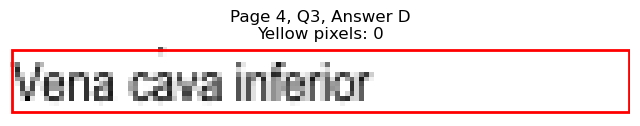


Page 4, Q3 - Selected Answer: B (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=240.9, x1=109.5, y1=253.5
Page 4, Q4, A: Yellow pixels: 92
Page 4, Q4, A: Total non-white pixels: 321
Page 4, Q4, A: Yellow percentage: 28.7%


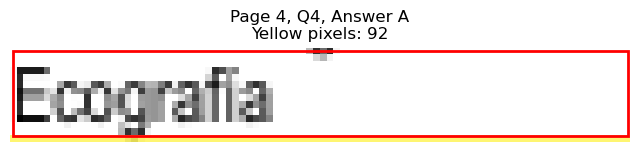

Page 4, Q4 - B: Detected box: x0=68.3, y0=253.5, x1=116.9, y1=266.1
Page 4, Q4, B: Yellow pixels: 1112
Page 4, Q4, B: Total non-white pixels: 1386
Page 4, Q4, B: Yellow percentage: 80.2%


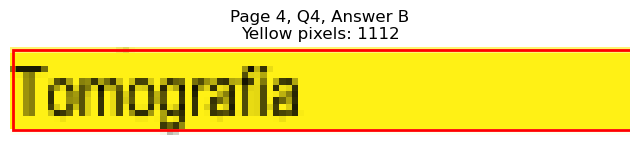

Page 4, Q4 - C: Detected box: x0=327.5, y0=240.9, x1=376.7, y1=253.5
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 284
Page 4, Q4, C: Yellow percentage: 0.0%


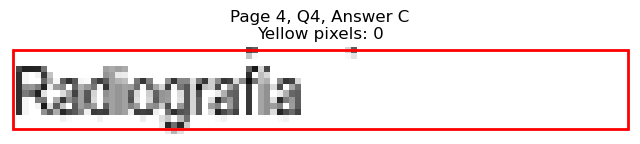

Page 4, Q4 - D: Detected box: x0=327.5, y0=253.5, x1=377.7, y1=266.1
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 262
Page 4, Q4, D: Yellow percentage: 0.0%


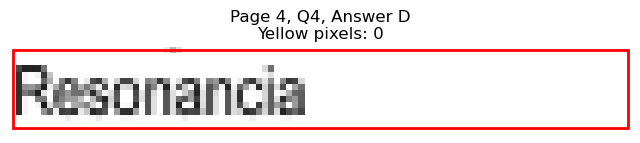


Page 4, Q4 - Selected Answer: B (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=291.4, x1=156.0, y1=304.1
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 459
Page 4, Q5, A: Yellow percentage: 0.0%


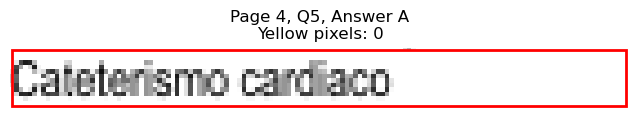

Page 4, Q5 - B: Detected box: x0=68.3, y0=304.0, x1=89.9, y1=316.7
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 109
Page 4, Q5, B: Yellow percentage: 0.0%


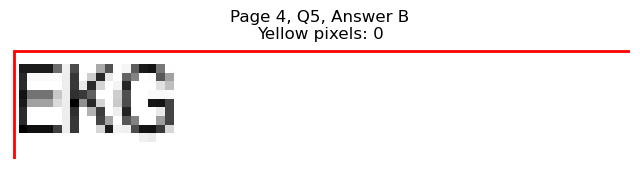

Page 4, Q5 - C: Detected box: x0=327.5, y0=291.4, x1=459.4, y1=304.1
Page 4, Q5, C: Yellow pixels: 183
Page 4, Q5, C: Total non-white pixels: 845
Page 4, Q5, C: Yellow percentage: 21.7%


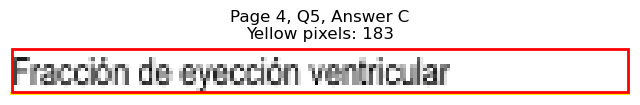

Page 4, Q5 - D: Detected box: x0=327.5, y0=304.0, x1=393.3, y1=316.7
Page 4, Q5, D: Yellow pixels: 1269
Page 4, Q5, D: Total non-white pixels: 1521
Page 4, Q5, D: Yellow percentage: 83.4%


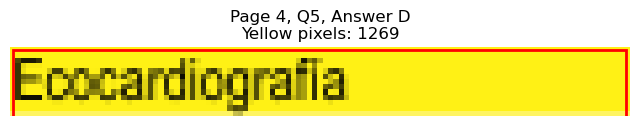


Page 4, Q5 - Selected Answer: D (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=341.9, x1=181.7, y1=354.6
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 589
Page 4, Q6, A: Yellow percentage: 0.0%


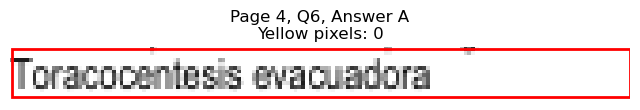

Page 4, Q6 - B: Detected box: x0=68.3, y0=354.5, x1=148.1, y1=367.2
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 411
Page 4, Q6, B: Yellow percentage: 0.0%


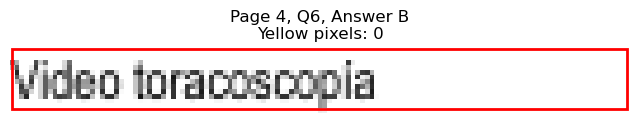

Page 4, Q6 - C: Detected box: x0=327.5, y0=341.9, x1=377.2, y1=354.6
Page 4, Q6, C: Yellow pixels: 101
Page 4, Q6, C: Total non-white pixels: 353
Page 4, Q6, C: Yellow percentage: 28.6%


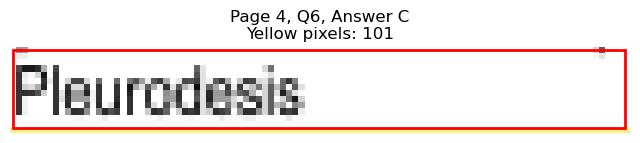

Page 4, Q6 - D: Detected box: x0=327.5, y0=354.5, x1=391.3, y1=367.2
Page 4, Q6, D: Yellow pixels: 1234
Page 4, Q6, D: Total non-white pixels: 1610
Page 4, Q6, D: Yellow percentage: 76.6%


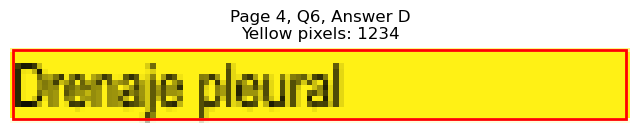


Page 4, Q6 - Selected Answer: D (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=417.6, x1=98.4, y1=430.3
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 175
Page 4, Q7, A: Yellow percentage: 0.0%


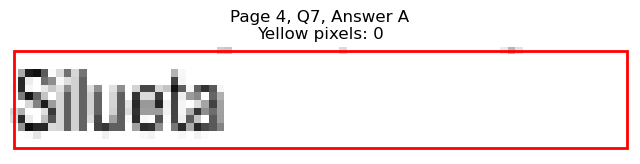

Page 4, Q7 - B: Detected box: x0=68.3, y0=430.2, x1=126.5, y1=442.9
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 271
Page 4, Q7, B: Yellow percentage: 0.0%


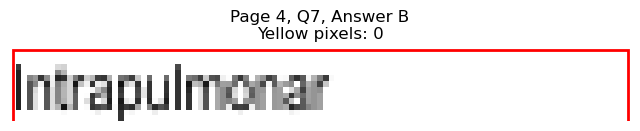

Page 4, Q7 - C: Detected box: x0=327.5, y0=417.6, x1=392.2, y1=430.3
Page 4, Q7, C: Yellow pixels: 116
Page 4, Q7, C: Total non-white pixels: 426
Page 4, Q7, C: Yellow percentage: 27.2%


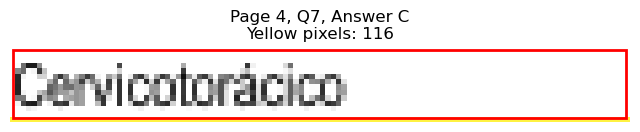

Page 4, Q7 - D: Detected box: x0=327.5, y0=430.2, x1=388.7, y1=442.9
Page 4, Q7, D: Yellow pixels: 1225
Page 4, Q7, D: Total non-white pixels: 1456
Page 4, Q7, D: Yellow percentage: 84.1%


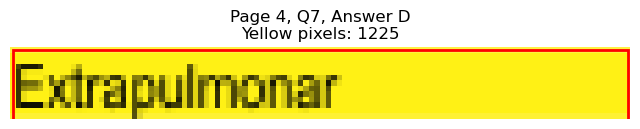


Page 4, Q7 - Selected Answer: D (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=468.1, x1=163.1, y1=480.7
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 491
Page 4, Q8, A: Yellow percentage: 0.0%


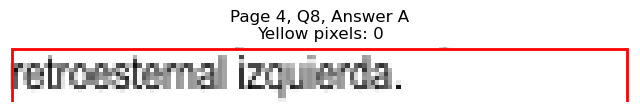

Page 4, Q8 - B: Detected box: x0=68.3, y0=480.8, x1=163.1, y1=493.4
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 487
Page 4, Q8, B: Yellow percentage: 0.0%


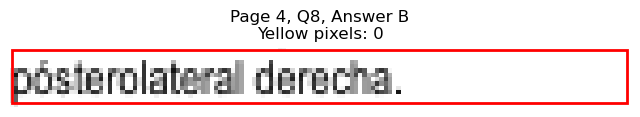

Page 4, Q8 - C: Detected box: x0=327.5, y0=468.1, x1=418.3, y1=480.7
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 469
Page 4, Q8, C: Yellow percentage: 0.0%


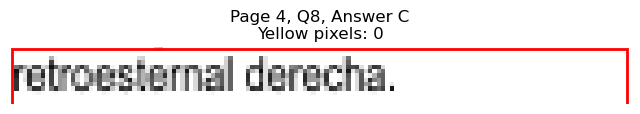

Page 4, Q8 - D: Detected box: x0=327.5, y0=480.8, x1=426.3, y1=493.4
Page 4, Q8, D: Yellow pixels: 1413
Page 4, Q8, D: Total non-white pixels: 2100
Page 4, Q8, D: Yellow percentage: 67.3%


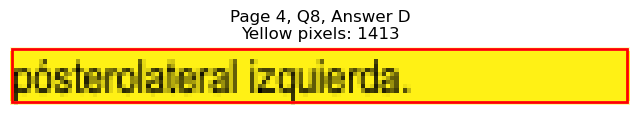


Page 4, Q8 - Selected Answer: D (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=543.8, x1=182.2, y1=556.4
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 598
Page 4, Q9, A: Yellow percentage: 0.0%


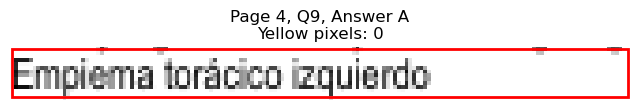

Page 4, Q9 - B: Detected box: x0=68.3, y0=556.5, x1=145.6, y1=569.2
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 372
Page 4, Q9, B: Yellow percentage: 0.0%


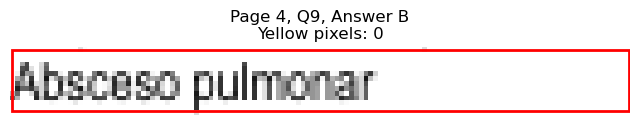

Page 4, Q9 - C: Detected box: x0=327.5, y0=543.8, x1=371.2, y1=556.4
Page 4, Q9, C: Yellow pixels: 1070
Page 4, Q9, C: Total non-white pixels: 1330
Page 4, Q9, C: Yellow percentage: 80.5%


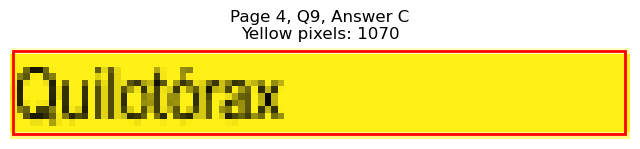

Page 4, Q9 - D: Detected box: x0=327.5, y0=556.5, x1=409.3, y1=569.2
Page 4, Q9, D: Yellow pixels: 133
Page 4, Q9, D: Total non-white pixels: 545
Page 4, Q9, D: Yellow percentage: 24.4%


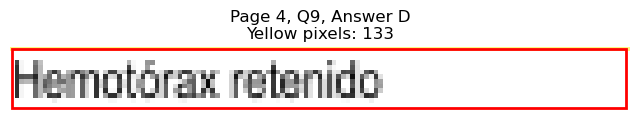


Page 4, Q9 - Selected Answer: C (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=68.3, y0=594.3, x1=133.0, y1=607.0
Page 4, Q10, A: Yellow pixels: 1256
Page 4, Q10, A: Total non-white pixels: 1495
Page 4, Q10, A: Yellow percentage: 84.0%


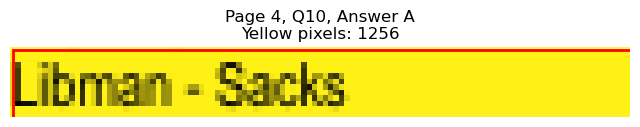

Page 4, Q10 - B: Detected box: x0=68.3, y0=606.9, x1=148.6, y1=619.6
Page 4, Q10, B: Yellow pixels: 131
Page 4, Q10, B: Total non-white pixels: 534
Page 4, Q10, B: Yellow percentage: 24.5%


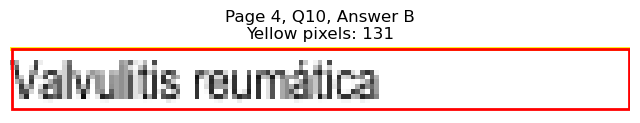

Page 4, Q10 - C: Detected box: x0=327.5, y0=594.3, x1=429.9, y1=607.0
Page 4, Q10, C: Yellow pixels: 0
Page 4, Q10, C: Total non-white pixels: 496
Page 4, Q10, C: Yellow percentage: 0.0%


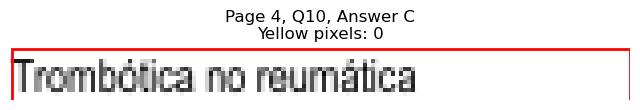

Page 4, Q10 - D: Detected box: x0=327.5, y0=606.9, x1=415.4, y1=619.6
Page 4, Q10, D: Yellow pixels: 0
Page 4, Q10, D: Total non-white pixels: 473
Page 4, Q10, D: Yellow percentage: 0.0%


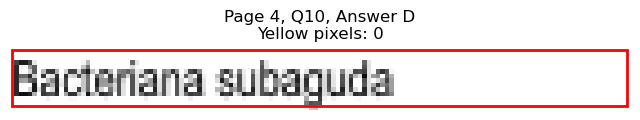


Page 4, Q10 - Selected Answer: A (based on yellow pixel count)




Page 4, Q11 - A: Detected box: x0=68.3, y0=670.1, x1=130.5, y1=682.7
Page 4, Q11, A: Yellow pixels: 0
Page 4, Q11, A: Total non-white pixels: 330
Page 4, Q11, A: Yellow percentage: 0.0%


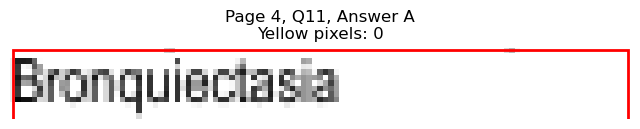

Page 4, Q11 - B: Detected box: x0=68.3, y0=682.7, x1=171.6, y1=695.3
Page 4, Q11, B: Yellow pixels: 0
Page 4, Q11, B: Total non-white pixels: 525
Page 4, Q11, B: Yellow percentage: 0.0%


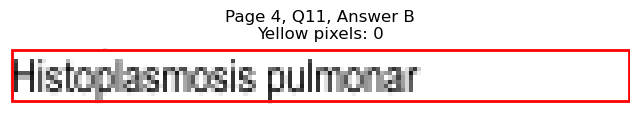

Page 4, Q11 - C: Detected box: x0=327.5, y0=670.1, x1=394.7, y1=682.7
Page 4, Q11, C: Yellow pixels: 0
Page 4, Q11, C: Total non-white pixels: 476
Page 4, Q11, C: Yellow percentage: 0.0%


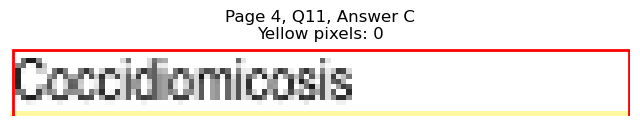

Page 4, Q11 - D: Detected box: x0=327.5, y0=682.7, x1=420.3, y1=695.3
Page 4, Q11, D: Yellow pixels: 1340
Page 4, Q11, D: Total non-white pixels: 2016
Page 4, Q11, D: Yellow percentage: 66.5%


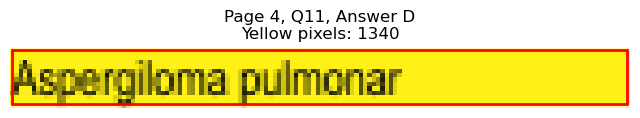


Page 4, Q11 - Selected Answer: D (based on yellow pixel count)




Page 4, Q12 - A: Detected box: x0=68.3, y0=745.8, x1=230.8, y1=758.4
Page 4, Q12, A: Yellow pixels: 0
Page 4, Q12, A: Total non-white pixels: 842
Page 4, Q12, A: Yellow percentage: 0.0%


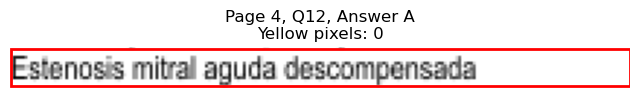

Page 4, Q12 - B: Detected box: x0=68.3, y0=758.5, x1=245.3, y1=771.2
Page 4, Q12, B: Yellow pixels: 2110
Page 4, Q12, B: Total non-white pixels: 2996
Page 4, Q12, B: Yellow percentage: 70.4%


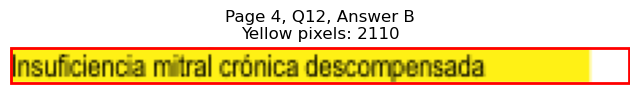

Page 4, Q12 - C: Detected box: x0=327.5, y0=745.8, x1=491.1, y1=758.4
Page 4, Q12, C: Yellow pixels: 0
Page 4, Q12, C: Total non-white pixels: 852
Page 4, Q12, C: Yellow percentage: 0.0%


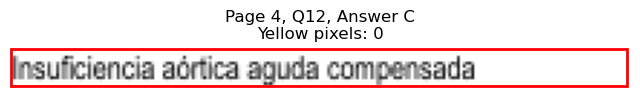

Page 4, Q12 - D: Detected box: x0=327.5, y0=758.5, x1=482.1, y1=771.2
Page 4, Q12, D: Yellow pixels: 0
Page 4, Q12, D: Total non-white pixels: 774
Page 4, Q12, D: Yellow percentage: 0.0%


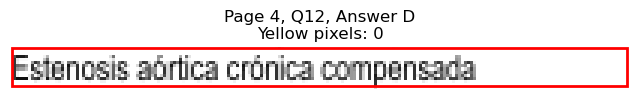


Page 4, Q12 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 10 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=145.6, y1=114.7
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 430
Page 5, Q1, A: Yellow percentage: 0.0%


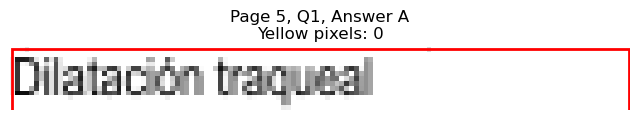

Page 5, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=184.1, y1=127.3
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 578
Page 5, Q1, B: Yellow percentage: 0.0%


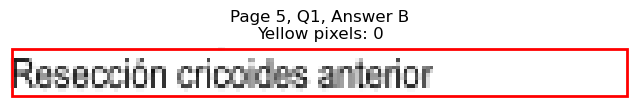

Page 5, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=449.9, y1=114.7
Page 5, Q1, C: Yellow pixels: 4
Page 5, Q1, C: Total non-white pixels: 819
Page 5, Q1, C: Yellow percentage: 0.5%


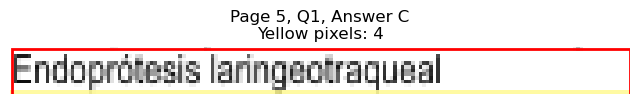

Page 5, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=448.9, y1=127.3
Page 5, Q1, D: Yellow pixels: 1625
Page 5, Q1, D: Total non-white pixels: 2408
Page 5, Q1, D: Yellow percentage: 67.5%


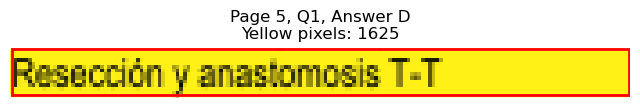


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=191.7, y1=165.2
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 602
Page 5, Q2, A: Yellow percentage: 0.0%


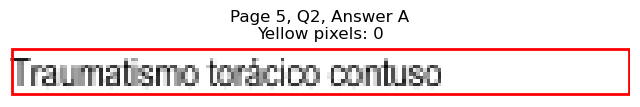

Page 5, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=168.1, y1=177.8
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 516
Page 5, Q2, B: Yellow percentage: 0.0%


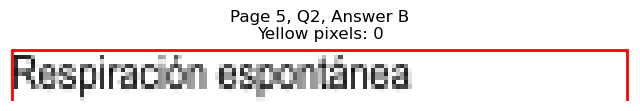

Page 5, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=445.4, y1=165.2
Page 5, Q2, C: Yellow pixels: 1764
Page 5, Q2, C: Total non-white pixels: 2366
Page 5, Q2, C: Yellow percentage: 74.6%


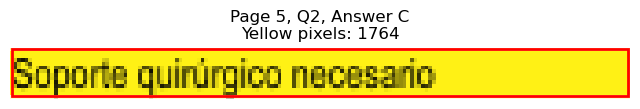

Page 5, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=467.0, y1=177.8
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 892
Page 5, Q2, D: Yellow percentage: 0.0%


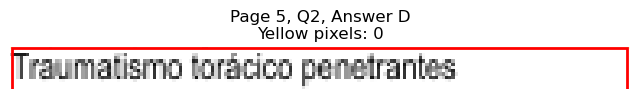


Page 5, Q2 - Selected Answer: C (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=169.6, y1=240.9
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 675
Page 5, Q3, A: Yellow percentage: 0.0%


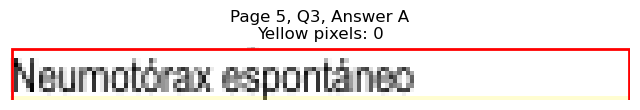

Page 5, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=150.0, y1=253.5
Page 5, Q3, B: Yellow pixels: 1398
Page 5, Q3, B: Total non-white pixels: 1862
Page 5, Q3, B: Yellow percentage: 75.1%


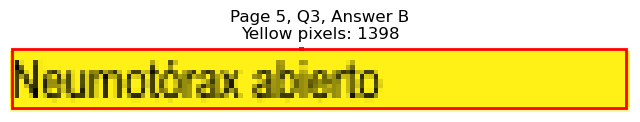

Page 5, Q3 - C: Detected box: x0=327.5, y0=228.3, x1=418.3, y1=240.9
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 460
Page 5, Q3, C: Yellow percentage: 0.0%


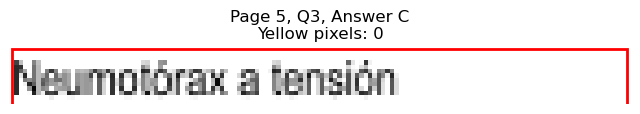

Page 5, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=401.7, y1=253.5
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 356
Page 5, Q3, D: Yellow percentage: 0.0%


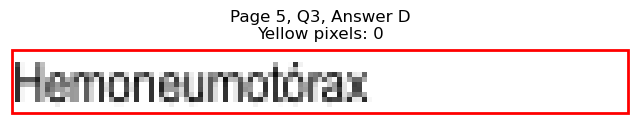


Page 5, Q3 - Selected Answer: B (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=217.7, y1=316.7
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 826
Page 5, Q4, A: Yellow percentage: 0.0%


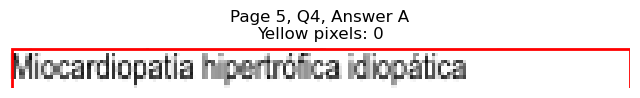

Page 5, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=168.6, y1=329.3
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 504
Page 5, Q4, B: Yellow percentage: 0.0%


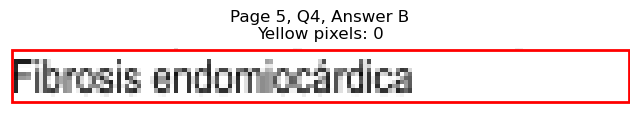

Page 5, Q4 - C: Detected box: x0=327.5, y0=304.0, x1=464.0, y1=316.7
Page 5, Q4, C: Yellow pixels: 1865
Page 5, Q4, C: Total non-white pixels: 2431
Page 5, Q4, C: Yellow percentage: 76.7%


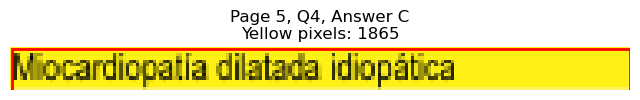

Page 5, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=422.8, y1=329.3
Page 5, Q4, D: Yellow pixels: 146
Page 5, Q4, D: Total non-white pixels: 613
Page 5, Q4, D: Yellow percentage: 23.8%


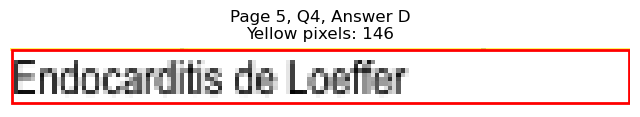


Page 5, Q4 - Selected Answer: C (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=184.7, y1=367.2
Page 5, Q5, A: Yellow pixels: 1707
Page 5, Q5, A: Total non-white pixels: 2338
Page 5, Q5, A: Yellow percentage: 73.0%


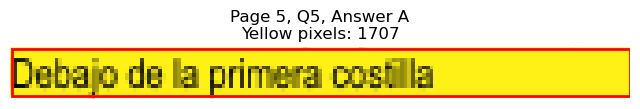

Page 5, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=206.8, y1=379.8
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 848
Page 5, Q5, B: Yellow percentage: 0.0%


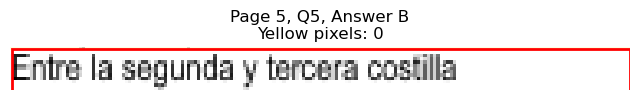

Page 5, Q5 - C: Detected box: x0=327.5, y0=354.5, x1=449.5, y1=367.2
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 597
Page 5, Q5, C: Yellow percentage: 0.0%


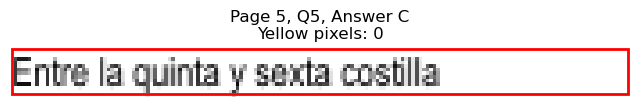

Page 5, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=505.2, y1=379.8
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 898
Page 5, Q5, D: Yellow percentage: 0.0%


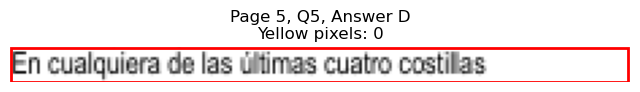


Page 5, Q5 - Selected Answer: A (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=417.6, x1=158.1, y1=430.3
Page 5, Q6, A: Yellow pixels: 1328
Page 5, Q6, A: Total non-white pixels: 1974
Page 5, Q6, A: Yellow percentage: 67.3%


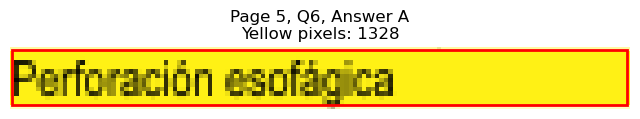

Page 5, Q6 - B: Detected box: x0=68.3, y0=430.2, x1=143.5, y1=442.9
Page 5, Q6, B: Yellow pixels: 0
Page 5, Q6, B: Total non-white pixels: 539
Page 5, Q6, B: Yellow percentage: 0.0%


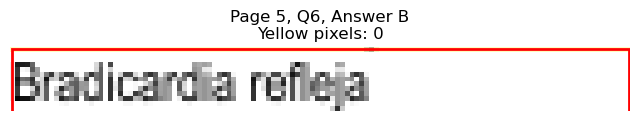

Page 5, Q6 - C: Detected box: x0=327.5, y0=228.3, x1=379.2, y1=240.9
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 460
Page 5, Q6, C: Yellow percentage: 0.0%


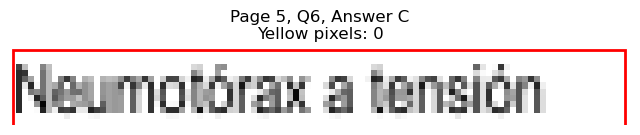

Page 5, Q6 - D: Detected box: x0=327.5, y0=430.2, x1=415.9, y1=442.9
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 436
Page 5, Q6, D: Yellow percentage: 0.0%


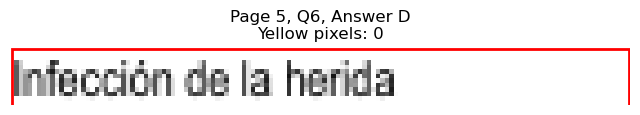


Page 5, Q6 - Selected Answer: A (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=493.4, x1=181.1, y1=506.0
Page 5, Q7, A: Yellow pixels: 1686
Page 5, Q7, A: Total non-white pixels: 2134
Page 5, Q7, A: Yellow percentage: 79.0%


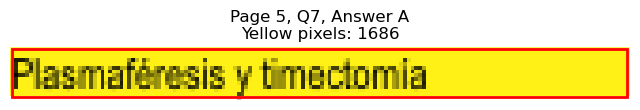

Page 5, Q7 - B: Detected box: x0=68.3, y0=506.0, x1=118.0, y1=518.6
Page 5, Q7, B: Yellow pixels: 98
Page 5, Q7, B: Total non-white pixels: 349
Page 5, Q7, B: Yellow percentage: 28.1%


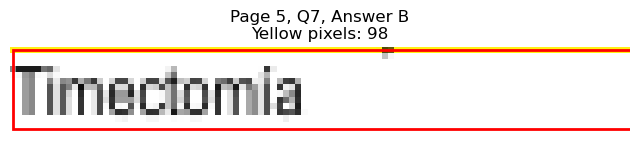

Page 5, Q7 - C: Detected box: x0=327.5, y0=493.4, x1=520.2, y1=506.0
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 991
Page 5, Q7, C: Yellow percentage: 0.0%


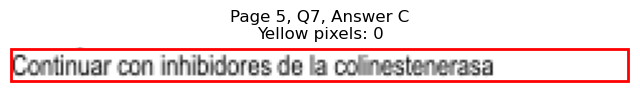

Page 5, Q7 - D: Detected box: x0=327.5, y0=506.0, x1=518.1, y1=518.6
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 1014
Page 5, Q7, D: Yellow percentage: 0.0%


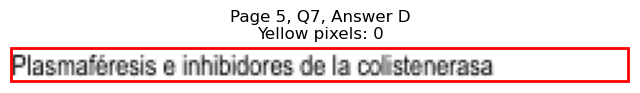


Page 5, Q7 - Selected Answer: A (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=556.5, x1=98.9, y1=569.2
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 99
Page 5, Q8, A: Yellow percentage: 0.0%


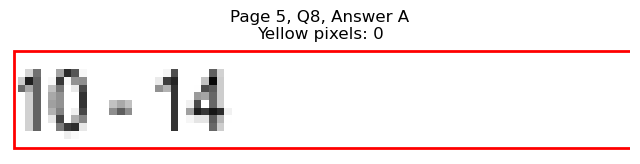

Page 5, Q8 - B: Detected box: x0=68.3, y0=569.1, x1=88.8, y1=581.8
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 59
Page 5, Q8, B: Yellow percentage: 0.0%


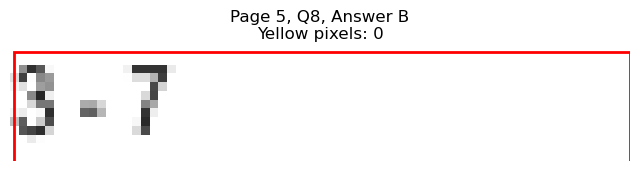

Page 5, Q8 - C: Detected box: x0=327.5, y0=556.5, x1=353.1, y1=569.2
Page 5, Q8, C: Yellow pixels: 946
Page 5, Q8, C: Total non-white pixels: 1078
Page 5, Q8, C: Yellow percentage: 87.8%


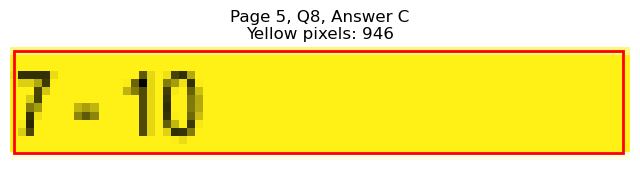

Page 5, Q8 - D: Detected box: x0=327.5, y0=569.1, x1=358.1, y1=581.8
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 190
Page 5, Q8, D: Yellow percentage: 0.0%


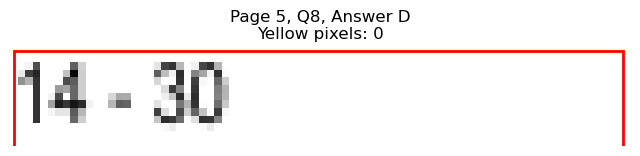


Page 5, Q8 - Selected Answer: C (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=619.6, x1=76.8, y1=632.3
Page 5, Q9, A: Yellow pixels: 0
Page 5, Q9, A: Total non-white pixels: 28
Page 5, Q9, A: Yellow percentage: 0.0%


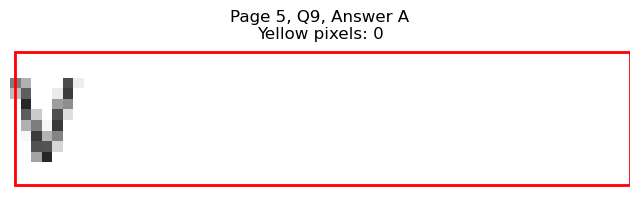

Page 5, Q9 - B: Detected box: x0=68.3, y0=632.2, x1=79.3, y1=644.9
Page 5, Q9, B: Yellow pixels: 0
Page 5, Q9, B: Total non-white pixels: 36
Page 5, Q9, B: Yellow percentage: 0.0%


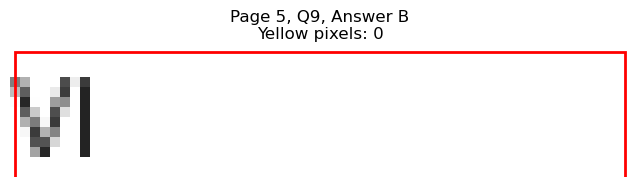

Page 5, Q9 - C: Detected box: x0=315.4, y0=619.6, x1=324.4, y1=632.3
Page 5, Q9, C: Yellow pixels: 60
Page 5, Q9, C: Total non-white pixels: 112
Page 5, Q9, C: Yellow percentage: 53.6%


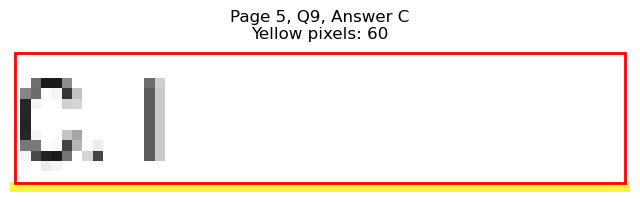

Page 5, Q9 - D: Detected box: x0=327.5, y0=632.2, x1=337.6, y1=644.9
Page 5, Q9, D: Yellow pixels: 753
Page 5, Q9, D: Total non-white pixels: 793
Page 5, Q9, D: Yellow percentage: 95.0%


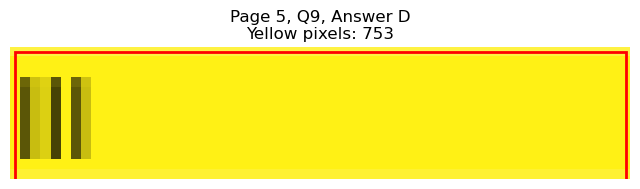


Page 5, Q9 - Selected Answer: D (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=68.3, y0=670.1, x1=244.4, y1=682.7
Page 5, Q10, A: Yellow pixels: 2125
Page 5, Q10, A: Total non-white pixels: 2782
Page 5, Q10, A: Yellow percentage: 76.4%


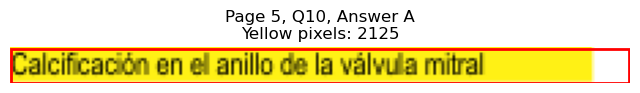

Page 5, Q10 - B: Detected box: x0=68.3, y0=682.7, x1=118.5, y1=695.3
Page 5, Q10, B: Yellow pixels: 101
Page 5, Q10, B: Total non-white pixels: 357
Page 5, Q10, B: Yellow percentage: 28.3%


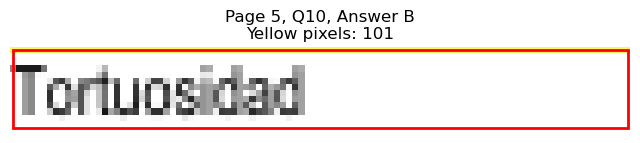

Page 5, Q10 - C: Detected box: x0=327.5, y0=670.1, x1=535.2, y1=682.7
Page 5, Q10, C: Yellow pixels: 0
Page 5, Q10, C: Total non-white pixels: 1070
Page 5, Q10, C: Yellow percentage: 0.0%


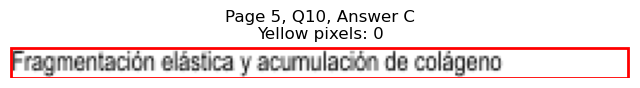

Page 5, Q10 - D: Detected box: x0=327.5, y0=682.7, x1=379.2, y1=695.3
Page 5, Q10, D: Yellow pixels: 0
Page 5, Q10, D: Total non-white pixels: 280
Page 5, Q10, D: Yellow percentage: 0.0%


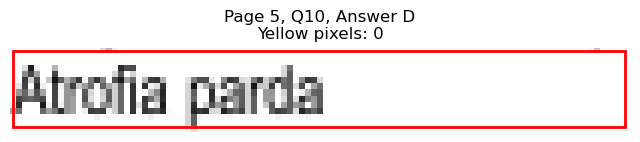


Page 5, Q10 - Selected Answer: A (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=178.3, y1=127.3
Page 6, Q1, A: Yellow pixels: 1538
Page 6, Q1, A: Total non-white pixels: 2254
Page 6, Q1, A: Yellow percentage: 68.2%


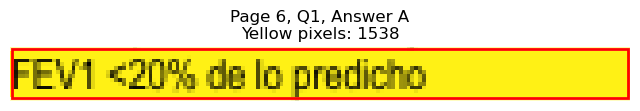

Page 6, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=180.9, y1=139.9
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 705
Page 6, Q1, B: Yellow percentage: 0.0%


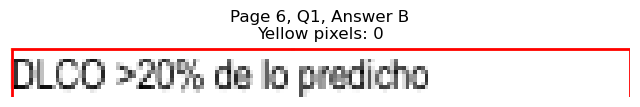

Page 6, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=178.8, y1=152.6
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 517
Page 6, Q1, C: Yellow percentage: 0.0%


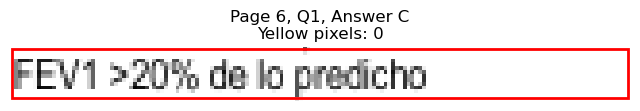

Page 6, Q1 - D: Detected box: x0=68.8, y0=152.5, x1=293.4, y1=165.2
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 1104
Page 6, Q1, D: Yellow percentage: 0.0%


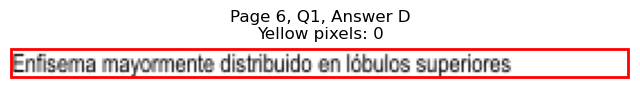


Page 6, Q1 - Selected Answer: A (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=205.7, y1=203.0
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 653
Page 6, Q2, A: Yellow percentage: 0.0%


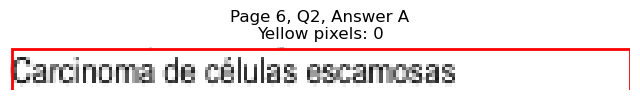

Page 6, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=160.1, y1=215.6
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 448
Page 6, Q2, B: Yellow percentage: 0.0%


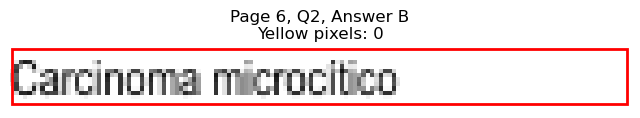

Page 6, Q2 - C: Detected box: x0=327.5, y0=190.3, x1=397.7, y1=203.0
Page 6, Q2, C: Yellow pixels: 1319
Page 6, Q2, C: Total non-white pixels: 1573
Page 6, Q2, C: Yellow percentage: 83.9%


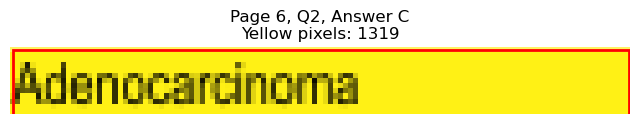

Page 6, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=366.2, y1=215.6
Page 6, Q2, D: Yellow pixels: 90
Page 6, Q2, D: Total non-white pixels: 278
Page 6, Q2, D: Yellow percentage: 32.4%


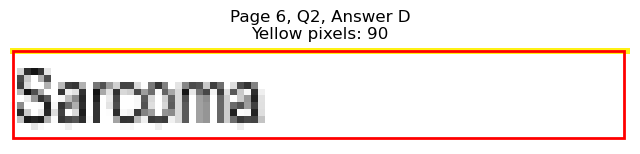


Page 6, Q2 - Selected Answer: C (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=170.2, y1=278.7
Page 6, Q3, A: Yellow pixels: 1607
Page 6, Q3, A: Total non-white pixels: 1989
Page 6, Q3, A: Yellow percentage: 80.8%


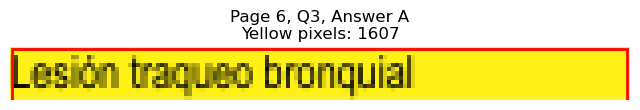

Page 6, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=149.5, y1=291.5
Page 6, Q3, B: Yellow pixels: 132
Page 6, Q3, B: Total non-white pixels: 514
Page 6, Q3, B: Yellow percentage: 25.7%


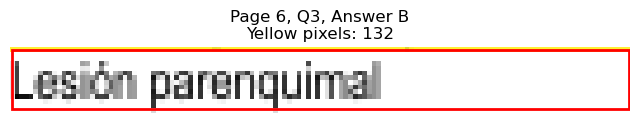

Page 6, Q3 - C: Detected box: x0=327.5, y0=266.1, x1=459.4, y1=278.7
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 672
Page 6, Q3, C: Yellow percentage: 0.0%


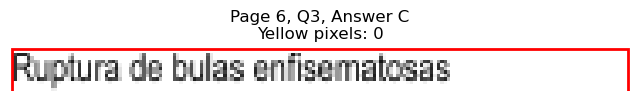

Page 6, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=398.7, y1=291.5
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 376
Page 6, Q3, D: Yellow percentage: 0.0%


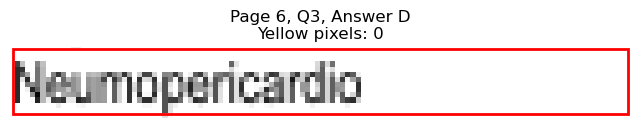


Page 6, Q3 - Selected Answer: A (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=168.6, y1=341.9
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 499
Page 6, Q4, A: Yellow percentage: 0.0%


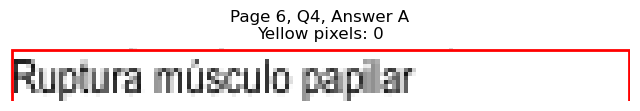

Page 6, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=148.1, y1=354.6
Page 6, Q4, B: Yellow pixels: 0
Page 6, Q4, B: Total non-white pixels: 404
Page 6, Q4, B: Yellow percentage: 0.0%


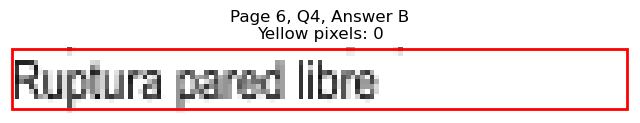

Page 6, Q4 - C: Detected box: x0=327.5, y0=329.2, x1=448.9, y1=341.9
Page 6, Q4, C: Yellow pixels: 1795
Page 6, Q4, C: Total non-white pixels: 2236
Page 6, Q4, C: Yellow percentage: 80.3%


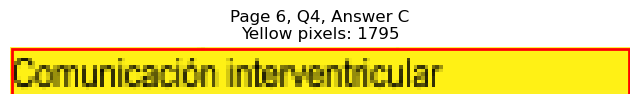

Page 6, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=456.4, y1=354.6
Page 6, Q4, D: Yellow pixels: 180
Page 6, Q4, D: Total non-white pixels: 829
Page 6, Q4, D: Yellow percentage: 21.7%


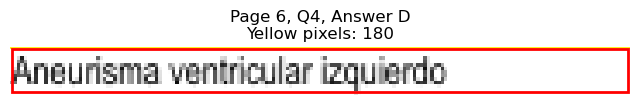


Page 6, Q4 - Selected Answer: C (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=165.6, y1=405.0
Page 6, Q5, A: Yellow pixels: 1551
Page 6, Q5, A: Total non-white pixels: 1924
Page 6, Q5, A: Yellow percentage: 80.6%


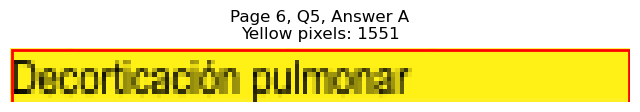

Page 6, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=144.0, y1=417.6
Page 6, Q5, B: Yellow pixels: 126
Page 6, Q5, B: Total non-white pixels: 520
Page 6, Q5, B: Yellow percentage: 24.2%


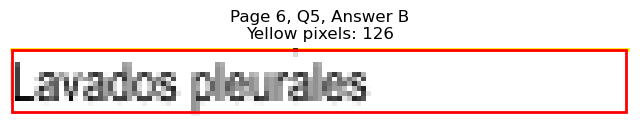

Page 6, Q5 - C: Detected box: x0=327.5, y0=392.3, x1=404.8, y1=405.0
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 395
Page 6, Q5, C: Yellow percentage: 0.0%


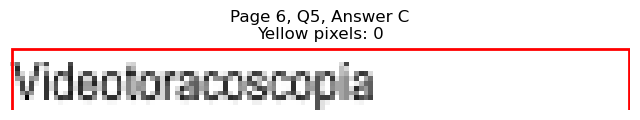

Page 6, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=481.7, y1=417.6
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 774
Page 6, Q5, D: Yellow percentage: 0.0%


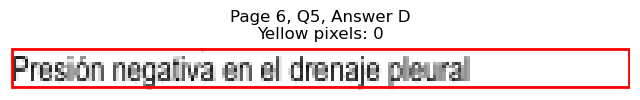


Page 6, Q5 - Selected Answer: A (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=157.1, y1=468.1
Page 6, Q6, A: Yellow pixels: 140
Page 6, Q6, A: Total non-white pixels: 573
Page 6, Q6, A: Yellow percentage: 24.4%


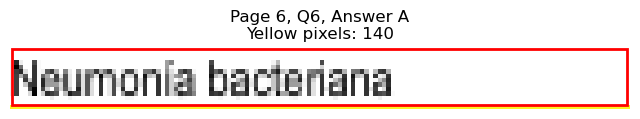

Page 6, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=164.5, y1=480.7
Page 6, Q6, B: Yellow pixels: 1515
Page 6, Q6, B: Total non-white pixels: 1911
Page 6, Q6, B: Yellow percentage: 79.3%


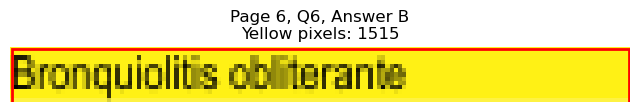

Page 6, Q6 - C: Detected box: x0=327.5, y0=455.5, x1=408.8, y1=468.1
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 423
Page 6, Q6, C: Yellow percentage: 0.0%


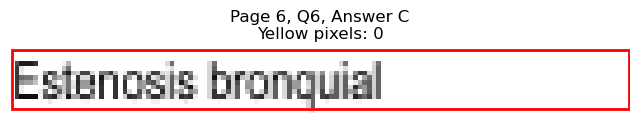

Page 6, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=437.3, y1=480.7
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 584
Page 6, Q6, D: Yellow percentage: 0.0%


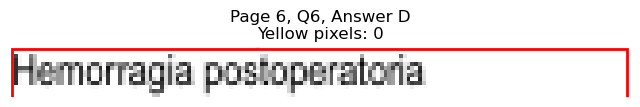


Page 6, Q6 - Selected Answer: B (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=147.0, y1=531.2
Page 6, Q7, A: Yellow pixels: 1398
Page 6, Q7, A: Total non-white pixels: 1820
Page 6, Q7, A: Yellow percentage: 76.8%


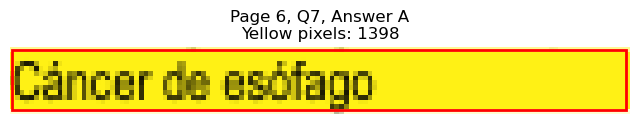

Page 6, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=121.5, y1=543.8
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 367
Page 6, Q7, B: Yellow percentage: 0.0%


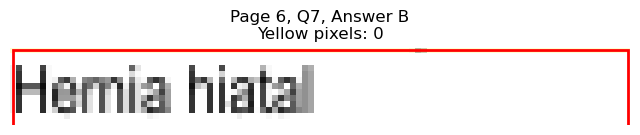

Page 6, Q7 - C: Detected box: x0=327.5, y0=518.6, x1=364.1, y1=531.2
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 191
Page 6, Q7, C: Yellow percentage: 0.0%


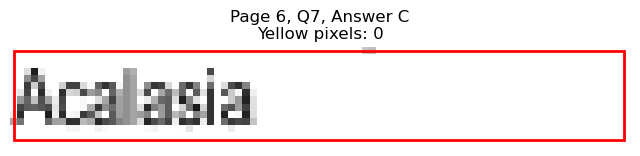

Page 6, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=413.8, y1=543.8
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 424
Page 6, Q7, D: Yellow percentage: 0.0%


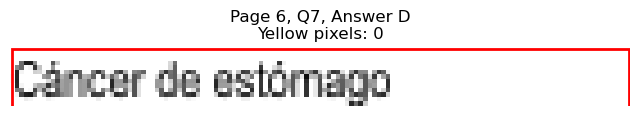


Page 6, Q7 - Selected Answer: A (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=569.1, x1=118.0, y1=581.8
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 249
Page 6, Q8, A: Yellow percentage: 0.0%


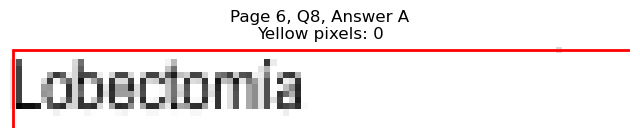

Page 6, Q8 - B: Detected box: x0=68.3, y0=581.7, x1=137.1, y1=594.4
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 351
Page 6, Q8, B: Yellow percentage: 0.0%


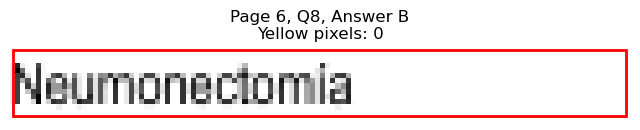

Page 6, Q8 - C: Detected box: x0=327.5, y0=569.1, x1=398.2, y1=581.8
Page 6, Q8, C: Yellow pixels: 2
Page 6, Q8, C: Total non-white pixels: 472
Page 6, Q8, C: Yellow percentage: 0.4%


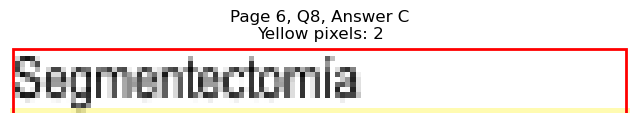

Page 6, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=464.0, y1=594.4
Page 6, Q8, D: Yellow pixels: 1731
Page 6, Q8, D: Total non-white pixels: 2618
Page 6, Q8, D: Yellow percentage: 66.1%


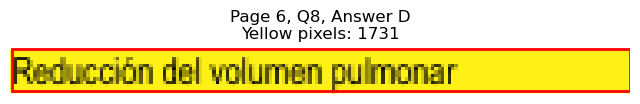


Page 6, Q8 - Selected Answer: D (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=619.6, x1=209.3, y1=632.3
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 689
Page 6, Q9, A: Yellow percentage: 0.0%


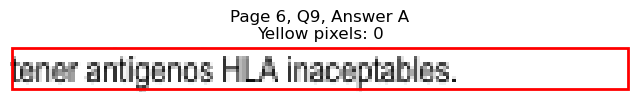

Page 6, Q9 - B: Detected box: x0=68.3, y0=632.2, x1=265.8, y1=644.9
Page 6, Q9, B: Yellow pixels: 26
Page 6, Q9, B: Total non-white pixels: 995
Page 6, Q9, B: Yellow percentage: 2.6%


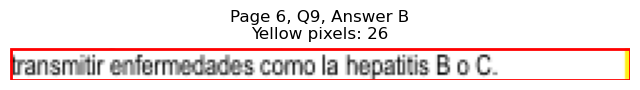

Page 6, Q9 - C: Detected box: x0=327.5, y0=619.6, x1=443.3, y1=632.3
Page 6, Q9, C: Yellow pixels: 167
Page 6, Q9, C: Total non-white pixels: 745
Page 6, Q9, C: Yellow percentage: 22.4%


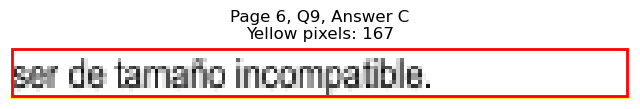

Page 6, Q9 - D: Detected box: x0=327.5, y0=632.2, x1=494.0, y1=644.9
Page 6, Q9, D: Yellow pixels: 2149
Page 6, Q9, D: Total non-white pixels: 2782
Page 6, Q9, D: Yellow percentage: 77.2%


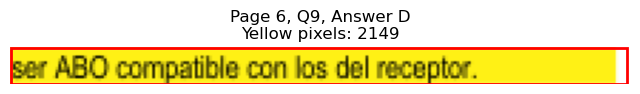


Page 6, Q9 - Selected Answer: D (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=68.3, y0=682.7, x1=136.0, y1=695.3
Page 6, Q10, A: Yellow pixels: 0
Page 6, Q10, A: Total non-white pixels: 336
Page 6, Q10, A: Yellow percentage: 0.0%


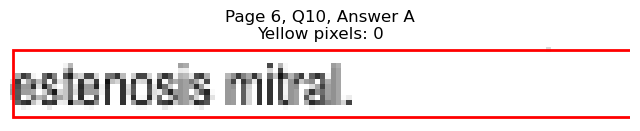

Page 6, Q10 - B: Detected box: x0=68.3, y0=695.4, x1=147.0, y1=708.0
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 390
Page 6, Q10, B: Yellow percentage: 0.0%


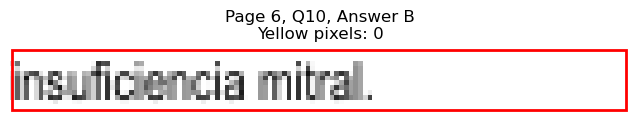

Page 6, Q10 - C: Detected box: x0=327.5, y0=682.7, x1=438.9, y1=695.3
Page 6, Q10, C: Yellow pixels: 0
Page 6, Q10, C: Total non-white pixels: 587
Page 6, Q10, C: Yellow percentage: 0.0%


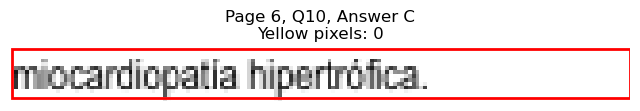

Page 6, Q10 - D: Detected box: x0=327.5, y0=695.4, x1=400.3, y1=708.0
Page 6, Q10, D: Yellow pixels: 1339
Page 6, Q10, D: Total non-white pixels: 1612
Page 6, Q10, D: Yellow percentage: 83.1%


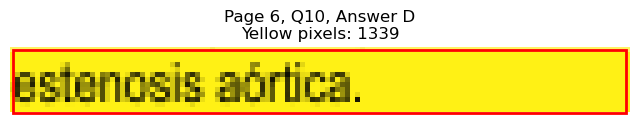


Page 6, Q10 - Selected Answer: D (based on yellow pixel count)





Page 7: Found 11 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=150.6, y1=127.3
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 426
Page 7, Q1, A: Yellow percentage: 0.0%


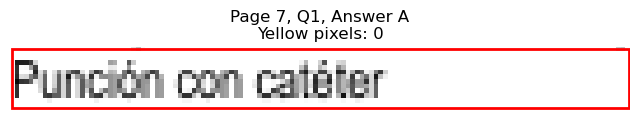

Page 7, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=148.1, y1=139.9
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 398
Page 7, Q1, B: Yellow percentage: 0.0%


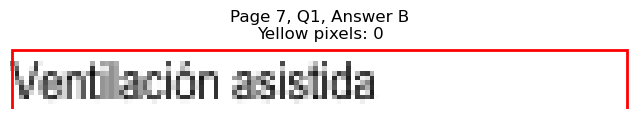

Page 7, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=413.3, y1=127.3
Page 7, Q1, C: Yellow pixels: 137
Page 7, Q1, C: Total non-white pixels: 588
Page 7, Q1, C: Yellow percentage: 23.3%


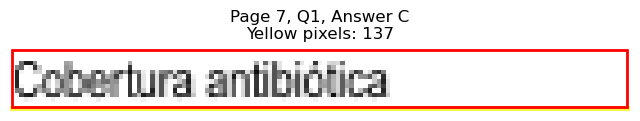

Page 7, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=395.7, y1=139.9
Page 7, Q1, D: Yellow pixels: 1260
Page 7, Q1, D: Total non-white pixels: 1547
Page 7, Q1, D: Yellow percentage: 81.4%


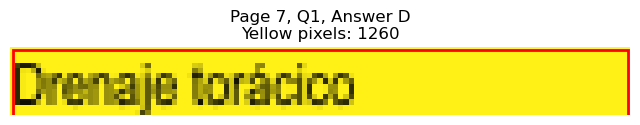


Page 7, Q1 - Selected Answer: D (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=136.5, y1=190.4
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 328
Page 7, Q2, A: Yellow percentage: 0.0%


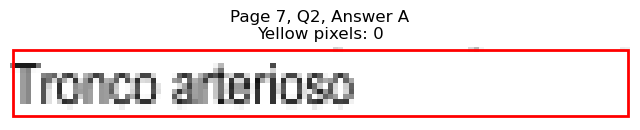

Page 7, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=214.7, y1=203.0
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 702
Page 7, Q2, B: Yellow percentage: 0.0%


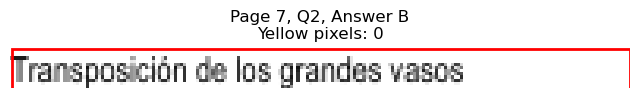

Page 7, Q2 - C: Detected box: x0=327.5, y0=177.7, x1=407.8, y1=190.4
Page 7, Q2, C: Yellow pixels: 1276
Page 7, Q2, C: Total non-white pixels: 1834
Page 7, Q2, C: Yellow percentage: 69.6%


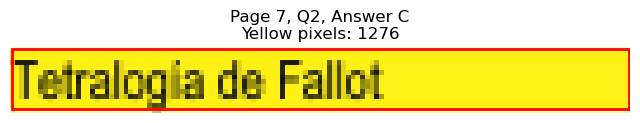

Page 7, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=419.0, y1=203.0
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 589
Page 7, Q2, D: Yellow percentage: 0.0%


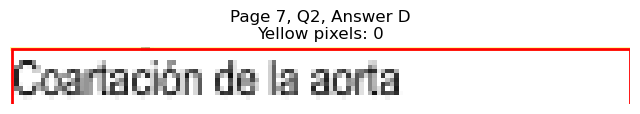


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=282.4, y1=253.5
Page 7, Q3, A: Yellow pixels: 1914
Page 7, Q3, A: Total non-white pixels: 3067
Page 7, Q3, A: Yellow percentage: 62.4%


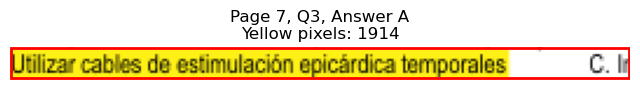

Page 7, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=176.2, y1=266.1
Page 7, Q3, B: Yellow pixels: 159
Page 7, Q3, B: Total non-white pixels: 685
Page 7, Q3, B: Yellow percentage: 23.2%


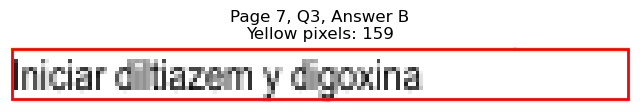

Page 7, Q3 - C: Detected box: x0=327.5, y0=240.9, x1=482.6, y1=253.5
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 815
Page 7, Q3, C: Yellow percentage: 0.0%


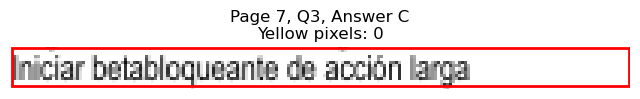

Page 7, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=403.3, y1=266.1
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 388
Page 7, Q3, D: Yellow percentage: 0.0%


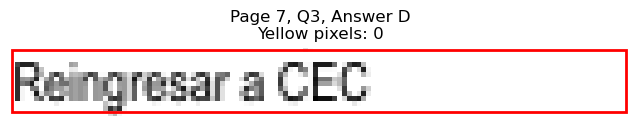


Page 7, Q3 - Selected Answer: A (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=257.8, y1=304.1
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 925
Page 7, Q4, A: Yellow percentage: 0.0%


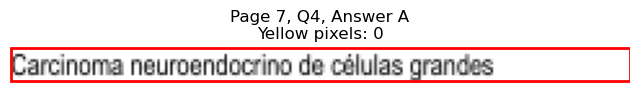

Page 7, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=199.7, y1=316.7
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 635
Page 7, Q4, B: Yellow percentage: 0.0%


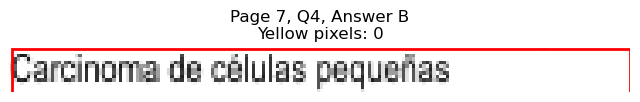

Page 7, Q4 - C: Detected box: x0=327.5, y0=291.4, x1=397.7, y1=304.1
Page 7, Q4, C: Yellow pixels: 1319
Page 7, Q4, C: Total non-white pixels: 1694
Page 7, Q4, C: Yellow percentage: 77.9%


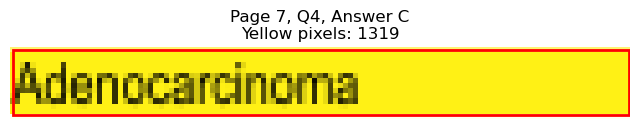

Page 7, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=425.8, y1=316.7
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 646
Page 7, Q4, D: Yellow percentage: 0.0%


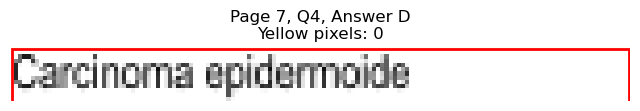


Page 7, Q4 - Selected Answer: C (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=234.8, y1=367.2
Page 7, Q5, A: Yellow pixels: 2119
Page 7, Q5, A: Total non-white pixels: 2996
Page 7, Q5, A: Yellow percentage: 70.7%


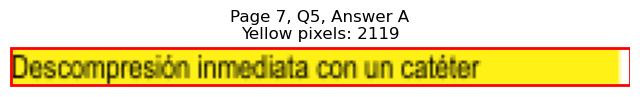

Page 7, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=242.3, y1=379.8
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 1073
Page 7, Q5, B: Yellow percentage: 0.0%


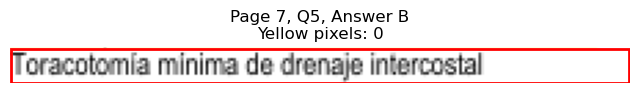

Page 7, Q5 - C: Detected box: x0=327.5, y0=354.5, x1=430.4, y1=367.2
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 521
Page 7, Q5, C: Yellow percentage: 0.0%


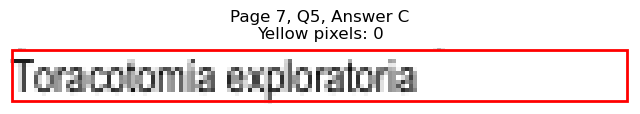

Page 7, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=425.3, y1=379.8
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 483
Page 7, Q5, D: Yellow percentage: 0.0%


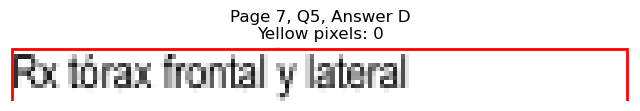


Page 7, Q5 - Selected Answer: A (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=404.9, x1=117.5, y1=417.6
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 262
Page 7, Q6, A: Yellow percentage: 0.0%


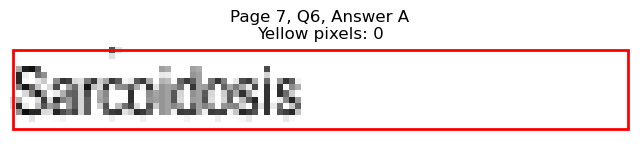

Page 7, Q6 - B: Detected box: x0=68.3, y0=417.6, x1=161.5, y1=430.3
Page 7, Q6, B: Yellow pixels: 1344
Page 7, Q6, B: Total non-white pixels: 2016
Page 7, Q6, B: Yellow percentage: 66.7%


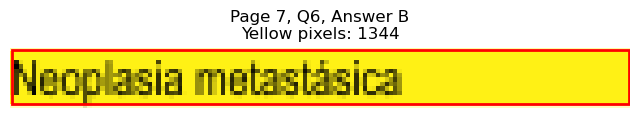

Page 7, Q6 - C: Detected box: x0=327.5, y0=404.9, x1=405.3, y1=417.6
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 408
Page 7, Q6, C: Yellow percentage: 0.0%


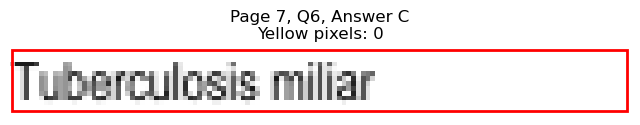

Page 7, Q6 - D: Detected box: x0=327.5, y0=417.6, x1=426.8, y1=430.3
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 536
Page 7, Q6, D: Yellow percentage: 0.0%


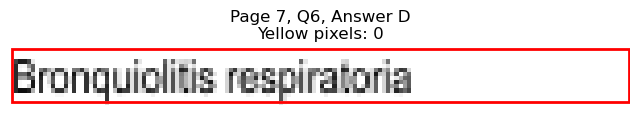


Page 7, Q6 - Selected Answer: B (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=468.1, x1=125.5, y1=480.7
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 282
Page 7, Q7, A: Yellow percentage: 0.0%


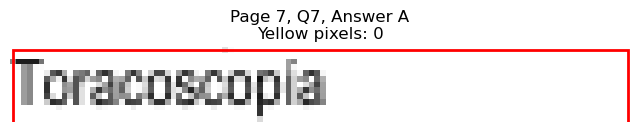

Page 7, Q7 - B: Detected box: x0=68.3, y0=480.8, x1=183.6, y1=493.4
Page 7, Q7, B: Yellow pixels: 1547
Page 7, Q7, B: Total non-white pixels: 2324
Page 7, Q7, B: Yellow percentage: 66.6%


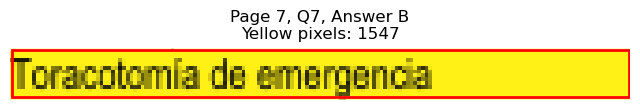

Page 7, Q7 - C: Detected box: x0=327.5, y0=468.1, x1=501.1, y1=480.7
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 862
Page 7, Q7, C: Yellow percentage: 0.0%


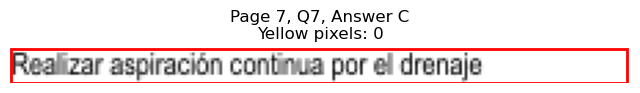

Page 7, Q7 - D: Detected box: x0=327.5, y0=480.8, x1=469.5, y1=493.4
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 715
Page 7, Q7, D: Yellow percentage: 0.0%


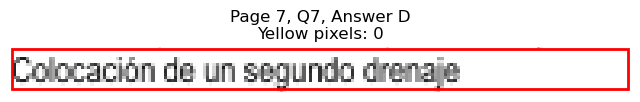


Page 7, Q7 - Selected Answer: B (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=531.2, x1=165.6, y1=543.8
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 484
Page 7, Q8, A: Yellow percentage: 0.0%


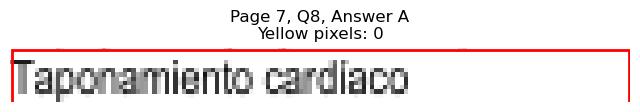

Page 7, Q8 - B: Detected box: x0=68.3, y0=543.8, x1=138.0, y1=556.4
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 331
Page 7, Q8, B: Yellow percentage: 0.0%


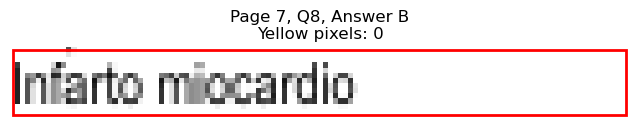

Page 7, Q8 - C: Detected box: x0=327.5, y0=531.2, x1=418.3, y1=543.8
Page 7, Q8, C: Yellow pixels: 1482
Page 7, Q8, C: Total non-white pixels: 1846
Page 7, Q8, C: Yellow percentage: 80.3%


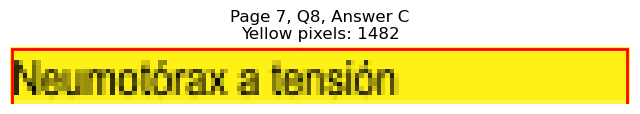

Page 7, Q8 - D: Detected box: x0=327.5, y0=543.8, x1=434.8, y1=556.4
Page 7, Q8, D: Yellow pixels: 158
Page 7, Q8, D: Total non-white pixels: 705
Page 7, Q8, D: Yellow percentage: 22.4%


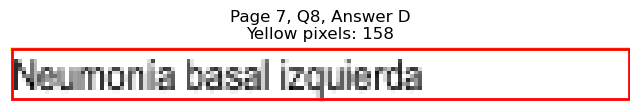


Page 7, Q8 - Selected Answer: C (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=594.3, x1=81.9, y1=607.0
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 65
Page 7, Q9, A: Yellow percentage: 0.0%


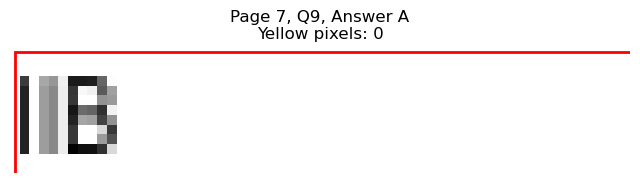

Page 7, Q9 - B: Detected box: x0=68.3, y0=606.9, x1=84.4, y1=619.6
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 70
Page 7, Q9, B: Yellow percentage: 0.0%


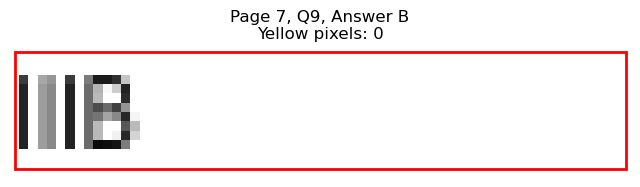

Page 7, Q9 - C: Detected box: x0=327.5, y0=594.3, x1=341.1, y1=607.0
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 130
Page 7, Q9, C: Yellow percentage: 0.0%


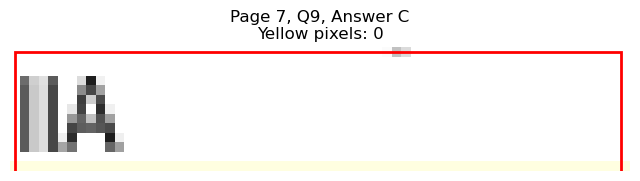

Page 7, Q9 - D: Detected box: x0=327.5, y0=606.9, x1=343.6, y1=619.6
Page 7, Q9, D: Yellow pixels: 803
Page 7, Q9, D: Total non-white pixels: 938
Page 7, Q9, D: Yellow percentage: 85.6%


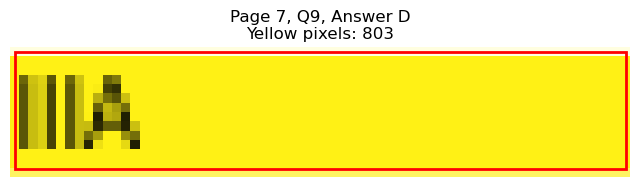


Page 7, Q9 - Selected Answer: D (based on yellow pixel count)




Page 7, Q10 - A: Detected box: x0=68.3, y0=644.9, x1=160.6, y1=657.5
Page 7, Q10, A: Yellow pixels: 0
Page 7, Q10, A: Total non-white pixels: 473
Page 7, Q10, A: Yellow percentage: 0.0%


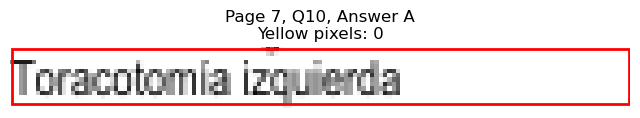

Page 7, Q10 - B: Detected box: x0=68.3, y0=657.5, x1=134.5, y1=670.1
Page 7, Q10, B: Yellow pixels: 0
Page 7, Q10, B: Total non-white pixels: 321
Page 7, Q10, B: Yellow percentage: 0.0%


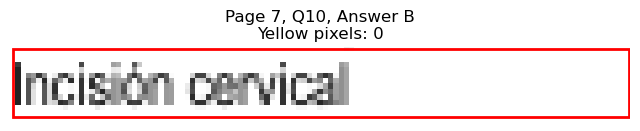

Page 7, Q10 - C: Detected box: x0=327.5, y0=644.9, x1=415.9, y1=657.5
Page 7, Q10, C: Yellow pixels: 1469
Page 7, Q10, C: Total non-white pixels: 1946
Page 7, Q10, C: Yellow percentage: 75.5%


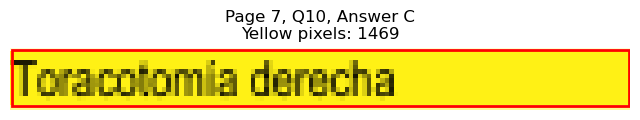

Page 7, Q10 - D: Detected box: x0=327.5, y0=657.5, x1=404.8, y1=670.1
Page 7, Q10, D: Yellow pixels: 128
Page 7, Q10, D: Total non-white pixels: 510
Page 7, Q10, D: Yellow percentage: 25.1%


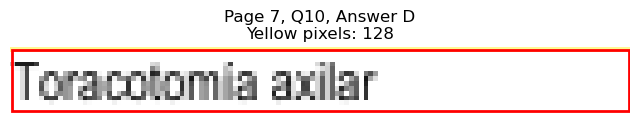


Page 7, Q10 - Selected Answer: C (based on yellow pixel count)




Page 7, Q11 - A: Detected box: x0=68.3, y0=720.6, x1=205.7, y1=733.2
Page 7, Q11, A: Yellow pixels: 188
Page 7, Q11, A: Total non-white pixels: 888
Page 7, Q11, A: Yellow percentage: 21.2%


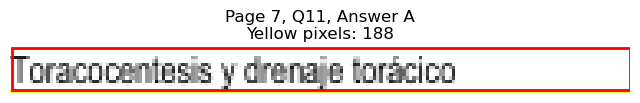

Page 7, Q11 - B: Detected box: x0=68.3, y0=733.2, x1=223.2, y1=745.8
Page 7, Q11, B: Yellow pixels: 2085
Page 7, Q11, B: Total non-white pixels: 2678
Page 7, Q11, B: Yellow percentage: 77.9%


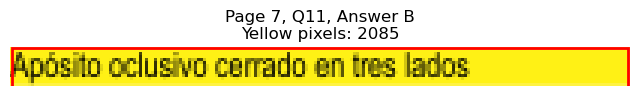

Page 7, Q11 - C: Detected box: x0=327.5, y0=720.6, x1=439.4, y1=733.2
Page 7, Q11, C: Yellow pixels: 0
Page 7, Q11, C: Total non-white pixels: 586
Page 7, Q11, C: Yellow percentage: 0.0%


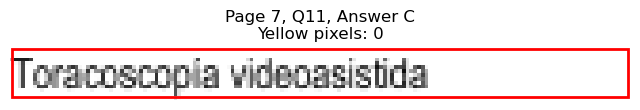

Page 7, Q11 - D: Detected box: x0=327.5, y0=733.2, x1=430.9, y1=745.8
Page 7, Q11, D: Yellow pixels: 0
Page 7, Q11, D: Total non-white pixels: 526
Page 7, Q11, D: Yellow percentage: 0.0%


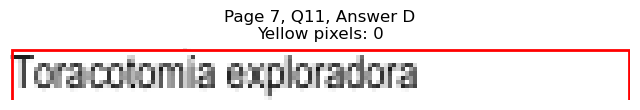


Page 7, Q11 - Selected Answer: B (based on yellow pixel count)





Page 8: Found 12 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=139.0, y1=114.7
Page 8, Q1, A: Yellow pixels: 3
Page 8, Q1, A: Total non-white pixels: 507
Page 8, Q1, A: Yellow percentage: 0.6%


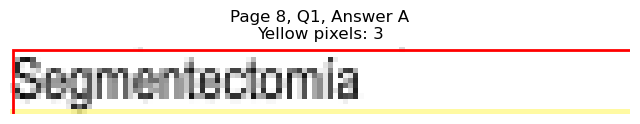

Page 8, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=222.3, y1=127.3
Page 8, Q1, B: Yellow pixels: 1900
Page 8, Q1, B: Total non-white pixels: 2870
Page 8, Q1, B: Yellow percentage: 66.2%


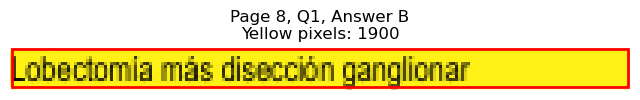

Page 8, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=396.3, y1=114.7
Page 8, Q1, C: Yellow pixels: 0
Page 8, Q1, C: Total non-white pixels: 337
Page 8, Q1, C: Yellow percentage: 0.0%


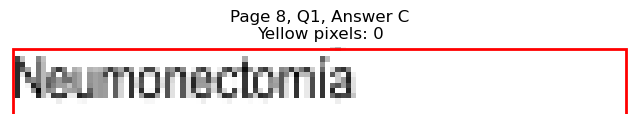

Page 8, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=445.4, y1=127.3
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 599
Page 8, Q1, D: Yellow percentage: 0.0%


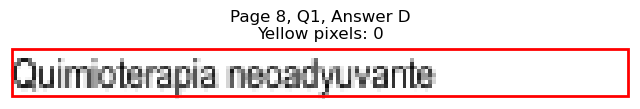


Page 8, Q1 - Selected Answer: B (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=193.7, y1=165.2
Page 8, Q2, A: Yellow pixels: 176
Page 8, Q2, A: Total non-white pixels: 794
Page 8, Q2, A: Yellow percentage: 22.2%


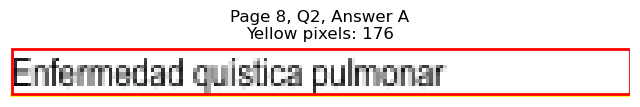

Page 8, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=207.3, y1=177.8
Page 8, Q2, B: Yellow pixels: 1952
Page 8, Q2, B: Total non-white pixels: 2470
Page 8, Q2, B: Yellow percentage: 79.0%


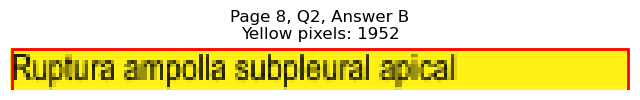

Page 8, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=436.4, y1=165.2
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 587
Page 8, Q2, C: Yellow percentage: 0.0%


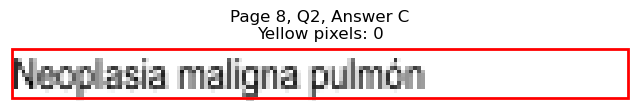

Page 8, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=407.8, y1=177.8
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 404
Page 8, Q2, D: Yellow percentage: 0.0%


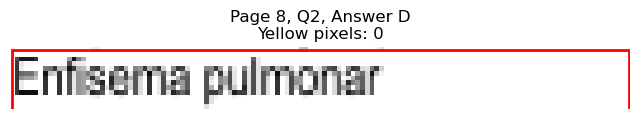


Page 8, Q2 - Selected Answer: B (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=202.9, x1=112.9, y1=215.6
Page 8, Q3, A: Yellow pixels: 1055
Page 8, Q3, A: Total non-white pixels: 1330
Page 8, Q3, A: Yellow percentage: 79.3%


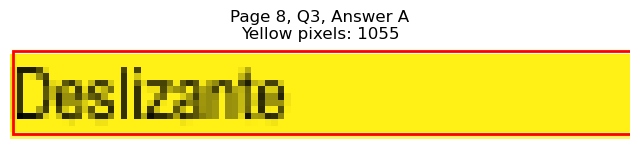

Page 8, Q3 - B: Detected box: x0=68.3, y0=215.7, x1=128.5, y1=228.3
Page 8, Q3, B: Yellow pixels: 111
Page 8, Q3, B: Total non-white pixels: 439
Page 8, Q3, B: Yellow percentage: 25.3%


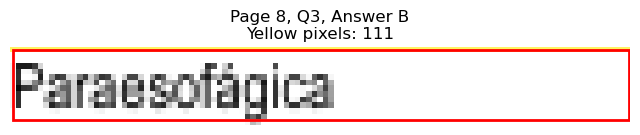

Page 8, Q3 - C: Detected box: x0=327.5, y0=202.9, x1=392.2, y1=215.6
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 350
Page 8, Q3, C: Yellow percentage: 0.0%


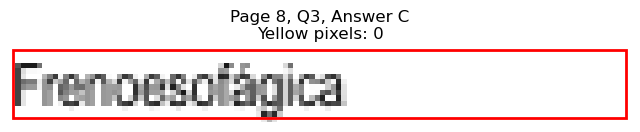

Page 8, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=385.7, y1=228.3
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 323
Page 8, Q3, D: Yellow percentage: 0.0%


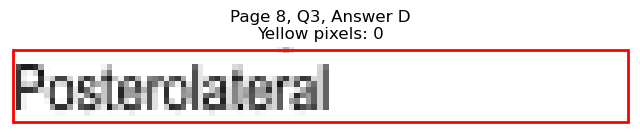


Page 8, Q3 - Selected Answer: A (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=253.5, x1=119.9, y1=266.1
Page 8, Q4, A: Yellow pixels: 102
Page 8, Q4, A: Total non-white pixels: 374
Page 8, Q4, A: Yellow percentage: 27.3%


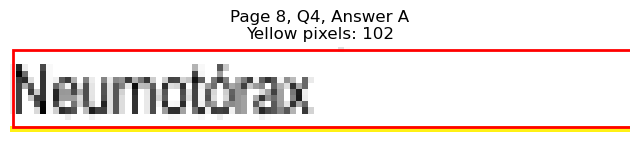

Page 8, Q4 - B: Detected box: x0=68.3, y0=266.1, x1=211.8, y1=278.7
Page 8, Q4, B: Yellow pixels: 1961
Page 8, Q4, B: Total non-white pixels: 2522
Page 8, Q4, B: Yellow percentage: 77.8%


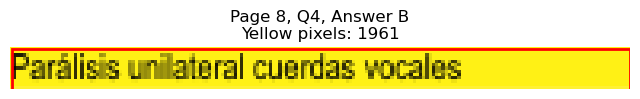

Page 8, Q4 - C: Detected box: x0=327.5, y0=253.5, x1=371.2, y1=266.1
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 226
Page 8, Q4, C: Yellow percentage: 0.0%


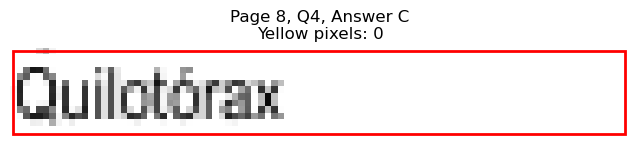

Page 8, Q4 - D: Detected box: x0=327.5, y0=266.1, x1=374.2, y1=278.7
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 233
Page 8, Q4, D: Yellow percentage: 0.0%


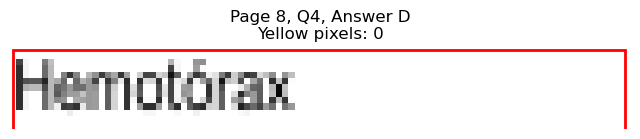


Page 8, Q4 - Selected Answer: B (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=304.0, x1=132.0, y1=316.7
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 309
Page 8, Q5, A: Yellow percentage: 0.0%


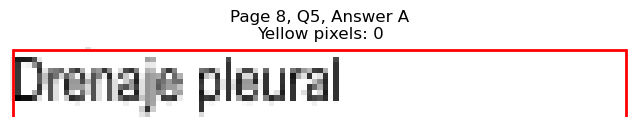

Page 8, Q5 - B: Detected box: x0=68.3, y0=316.6, x1=125.5, y1=329.3
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 284
Page 8, Q5, B: Yellow percentage: 0.0%


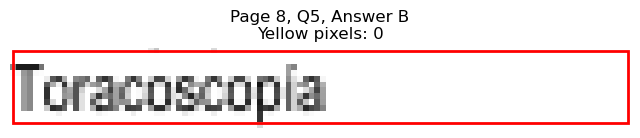

Page 8, Q5 - C: Detected box: x0=327.5, y0=304.0, x1=391.3, y1=316.7
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 436
Page 8, Q5, C: Yellow percentage: 0.0%


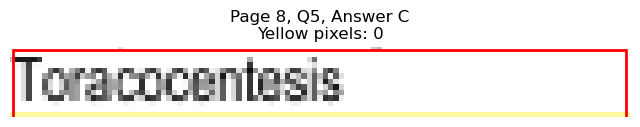

Page 8, Q5 - D: Detected box: x0=327.5, y0=316.6, x1=377.2, y1=329.3
Page 8, Q5, D: Yellow pixels: 1031
Page 8, Q5, D: Total non-white pixels: 1414
Page 8, Q5, D: Yellow percentage: 72.9%


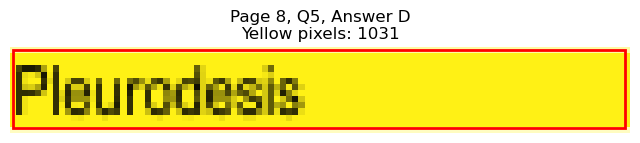


Page 8, Q5 - Selected Answer: D (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=379.7, x1=151.6, y1=392.4
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 444
Page 8, Q6, A: Yellow percentage: 0.0%


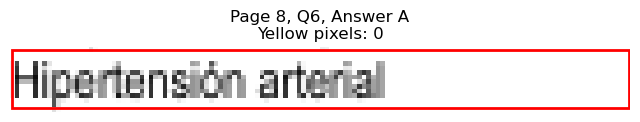

Page 8, Q6 - B: Detected box: x0=68.3, y0=392.3, x1=137.5, y1=405.0
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 339
Page 8, Q6, B: Yellow percentage: 0.0%


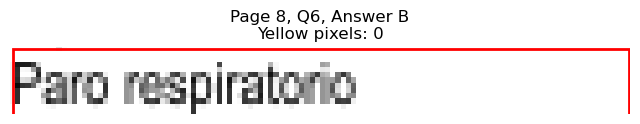

Page 8, Q6 - C: Detected box: x0=327.5, y0=379.7, x1=416.3, y1=392.4
Page 8, Q6, C: Yellow pixels: 1317
Page 8, Q6, C: Total non-white pixels: 1960
Page 8, Q6, C: Yellow percentage: 67.2%


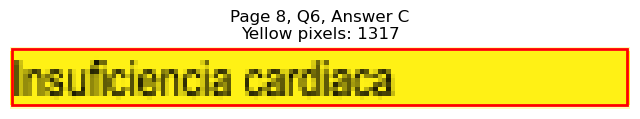

Page 8, Q6 - D: Detected box: x0=327.5, y0=392.3, x1=426.8, y1=405.0
Page 8, Q6, D: Yellow pixels: 0
Page 8, Q6, D: Total non-white pixels: 639
Page 8, Q6, D: Yellow percentage: 0.0%


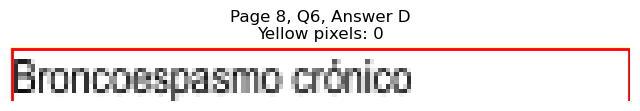


Page 8, Q6 - Selected Answer: C (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=430.2, x1=143.5, y1=442.9
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 536
Page 8, Q7, A: Yellow percentage: 0.0%


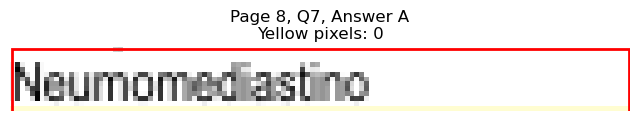

Page 8, Q7 - B: Detected box: x0=68.3, y0=442.8, x1=135.5, y1=455.5
Page 8, Q7, B: Yellow pixels: 1248
Page 8, Q7, B: Total non-white pixels: 1652
Page 8, Q7, B: Yellow percentage: 75.5%


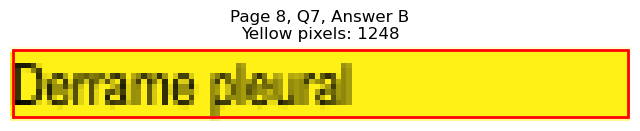

Page 8, Q7 - C: Detected box: x0=327.5, y0=430.2, x1=416.8, y1=442.9
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 455
Page 8, Q7, C: Yellow percentage: 0.0%


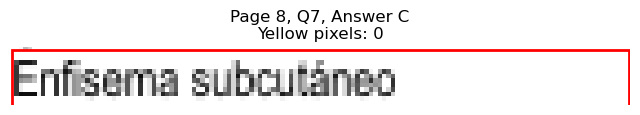

Page 8, Q7 - D: Detected box: x0=327.5, y0=442.8, x1=458.5, y1=455.5
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 660
Page 8, Q7, D: Yellow percentage: 0.0%


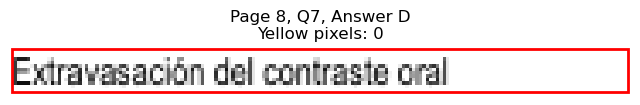


Page 8, Q7 - Selected Answer: B (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=506.0, x1=155.1, y1=518.6
Page 8, Q8, A: Yellow pixels: 1431
Page 8, Q8, A: Total non-white pixels: 1932
Page 8, Q8, A: Yellow percentage: 74.1%


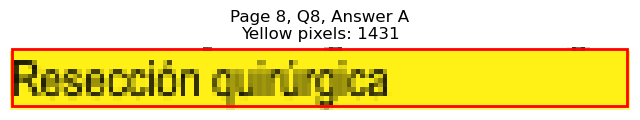

Page 8, Q8 - B: Detected box: x0=68.3, y0=518.6, x1=121.9, y1=531.2
Page 8, Q8, B: Yellow pixels: 103
Page 8, Q8, B: Total non-white pixels: 387
Page 8, Q8, B: Yellow percentage: 26.6%


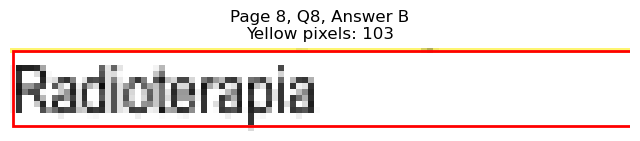

Page 8, Q8 - C: Detected box: x0=327.5, y0=506.0, x1=386.2, y1=518.6
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 308
Page 8, Q8, C: Yellow percentage: 0.0%


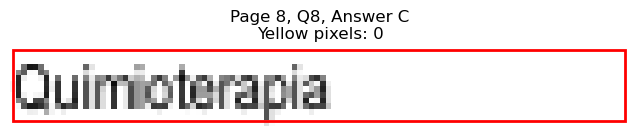

Page 8, Q8 - D: Detected box: x0=327.5, y0=518.6, x1=404.8, y1=531.2
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 402
Page 8, Q8, D: Yellow percentage: 0.0%


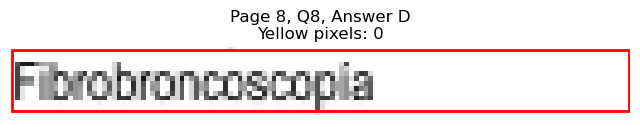


Page 8, Q8 - Selected Answer: A (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=304.0, x1=132.0, y1=316.7
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 309
Page 8, Q9, A: Yellow percentage: 0.0%


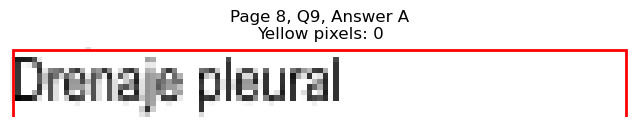

Page 8, Q9 - B: Detected box: x0=68.3, y0=632.2, x1=132.1, y1=644.9
Page 8, Q9, B: Yellow pixels: 0
Page 8, Q9, B: Total non-white pixels: 579
Page 8, Q9, B: Yellow percentage: 0.0%


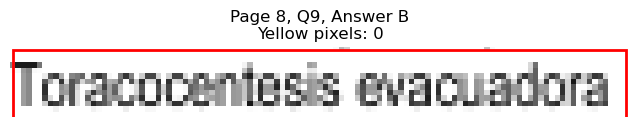

Page 8, Q9 - C: Detected box: x0=327.5, y0=556.5, x1=384.8, y1=569.2
Page 8, Q9, C: Yellow pixels: 1186
Page 8, Q9, C: Total non-white pixels: 1512
Page 8, Q9, C: Yellow percentage: 78.4%


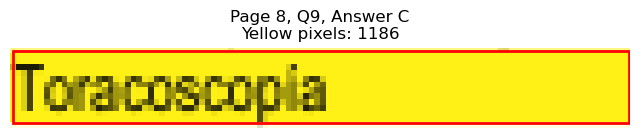

Page 8, Q9 - D: Detected box: x0=327.5, y0=569.1, x1=389.2, y1=581.8
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 441
Page 8, Q9, D: Yellow percentage: 0.0%


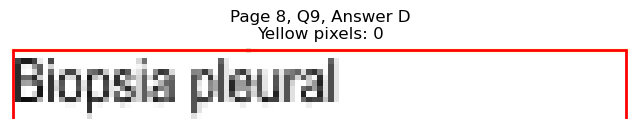


Page 8, Q9 - Selected Answer: C (based on yellow pixel count)




Page 8, Q10 - A: Detected box: x0=68.3, y0=619.6, x1=253.4, y1=632.3
Page 8, Q10, A: Yellow pixels: 0
Page 8, Q10, A: Total non-white pixels: 932
Page 8, Q10, A: Yellow percentage: 0.0%


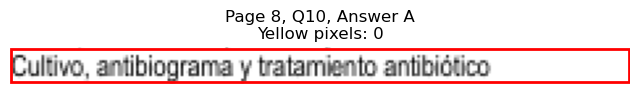

Page 8, Q10 - B: Detected box: x0=68.3, y0=632.2, x1=181.7, y1=644.9
Page 8, Q10, B: Yellow pixels: 0
Page 8, Q10, B: Total non-white pixels: 579
Page 8, Q10, B: Yellow percentage: 0.0%


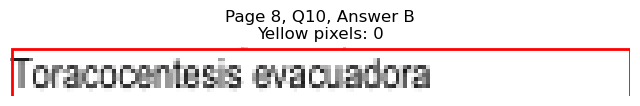

Page 8, Q10 - C: Detected box: x0=327.5, y0=619.6, x1=392.2, y1=632.3
Page 8, Q10, C: Yellow pixels: 1126
Page 8, Q10, C: Total non-white pixels: 1624
Page 8, Q10, C: Yellow percentage: 69.3%


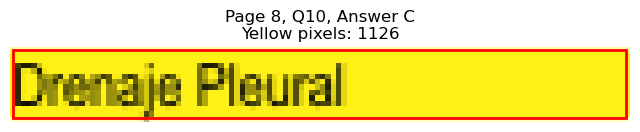

Page 8, Q10 - D: Detected box: x0=327.5, y0=632.2, x1=533.3, y1=644.9
Page 8, Q10, D: Yellow pixels: 0
Page 8, Q10, D: Total non-white pixels: 1229
Page 8, Q10, D: Yellow percentage: 0.0%


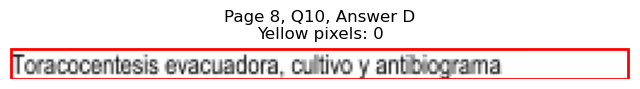


Page 8, Q10 - Selected Answer: C (based on yellow pixel count)




Page 8, Q11 - A: Detected box: x0=68.3, y0=670.1, x1=163.1, y1=682.7
Page 8, Q11, A: Yellow pixels: 0
Page 8, Q11, A: Total non-white pixels: 661
Page 8, Q11, A: Yellow percentage: 0.0%


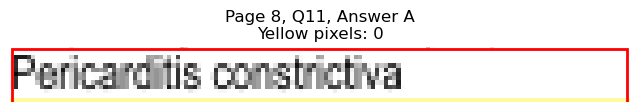

Page 8, Q11 - B: Detected box: x0=68.3, y0=682.7, x1=166.1, y1=695.3
Page 8, Q11, B: Yellow pixels: 1409
Page 8, Q11, B: Total non-white pixels: 2086
Page 8, Q11, B: Yellow percentage: 67.5%


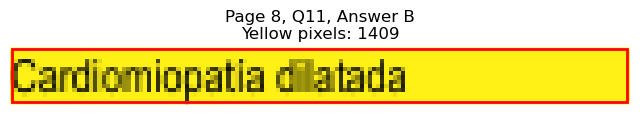

Page 8, Q11 - C: Detected box: x0=327.5, y0=670.1, x1=410.3, y1=682.7
Page 8, Q11, C: Yellow pixels: 0
Page 8, Q11, C: Total non-white pixels: 433
Page 8, Q11, C: Yellow percentage: 0.0%


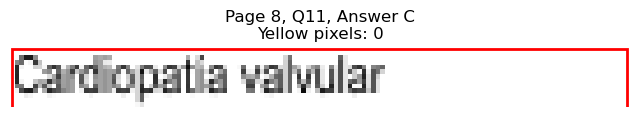

Page 8, Q11 - D: Detected box: x0=327.5, y0=682.7, x1=422.3, y1=695.3
Page 8, Q11, D: Yellow pixels: 0
Page 8, Q11, D: Total non-white pixels: 476
Page 8, Q11, D: Yellow percentage: 0.0%


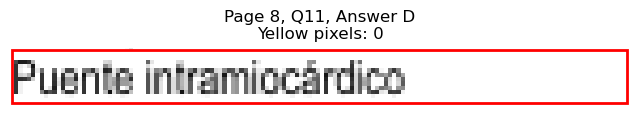


Page 8, Q11 - Selected Answer: B (based on yellow pixel count)




Page 8, Q12 - A: Detected box: x0=68.3, y0=720.6, x1=192.7, y1=733.2
Page 8, Q12, A: Yellow pixels: 1782
Page 8, Q12, A: Total non-white pixels: 2450
Page 8, Q12, A: Yellow percentage: 72.7%


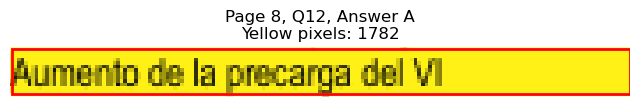

Page 8, Q12 - B: Detected box: x0=68.3, y0=733.2, x1=209.8, y1=745.8
Page 8, Q12, B: Yellow pixels: 0
Page 8, Q12, B: Total non-white pixels: 898
Page 8, Q12, B: Yellow percentage: 0.0%


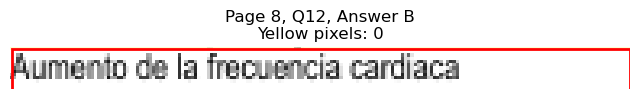

Page 8, Q12 - C: Detected box: x0=327.5, y0=720.6, x1=509.6, y1=733.2
Page 8, Q12, C: Yellow pixels: 0
Page 8, Q12, C: Total non-white pixels: 886
Page 8, Q12, C: Yellow percentage: 0.0%


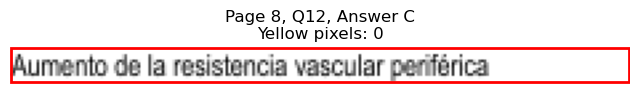

Page 8, Q12 - D: Detected box: x0=327.5, y0=733.2, x1=498.1, y1=745.8
Page 8, Q12, D: Yellow pixels: 0
Page 8, Q12, D: Total non-white pixels: 897
Page 8, Q12, D: Yellow percentage: 0.0%


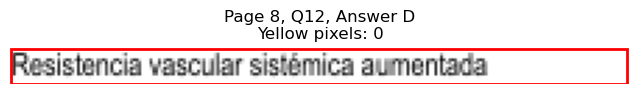


Page 8, Q12 - Selected Answer: A (based on yellow pixel count)





Page 9: Found 11 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=164.1, y1=114.7
Page 9, Q1, A: Yellow pixels: 1512
Page 9, Q1, A: Total non-white pixels: 1911
Page 9, Q1, A: Yellow percentage: 79.1%


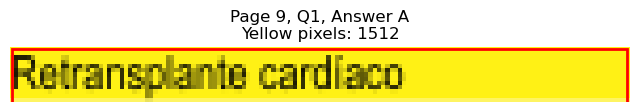

Page 9, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=201.8, y1=127.3
Page 9, Q1, B: Yellow pixels: 184
Page 9, Q1, B: Total non-white pixels: 825
Page 9, Q1, B: Yellow percentage: 22.3%


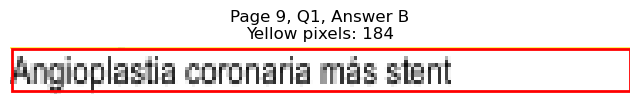

Page 9, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=504.7, y1=114.7
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 884
Page 9, Q1, C: Yellow percentage: 0.0%


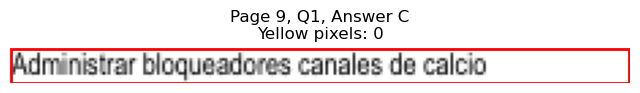

Page 9, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=414.3, y1=127.3
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 457
Page 9, Q1, D: Yellow percentage: 0.0%


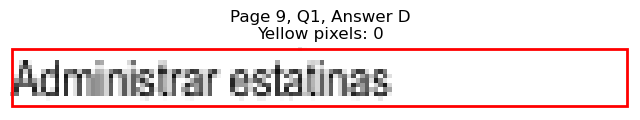


Page 9, Q1 - Selected Answer: A (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=204.2, y1=177.8
Page 9, Q2, A: Yellow pixels: 1892
Page 9, Q2, A: Total non-white pixels: 2431
Page 9, Q2, A: Yellow percentage: 77.8%


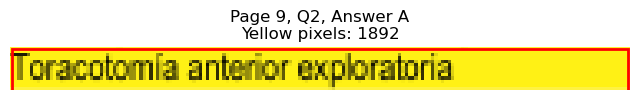

Page 9, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=151.6, y1=190.4
Page 9, Q2, B: Yellow pixels: 134
Page 9, Q2, B: Total non-white pixels: 557
Page 9, Q2, B: Yellow percentage: 24.1%


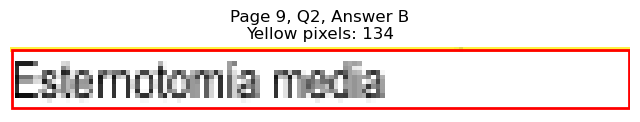

Page 9, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=404.8, y1=177.8
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 382
Page 9, Q2, C: Yellow percentage: 0.0%


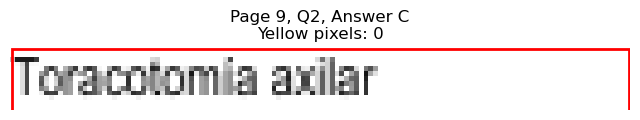

Page 9, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=437.8, y1=190.4
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 565
Page 9, Q2, D: Yellow percentage: 0.0%


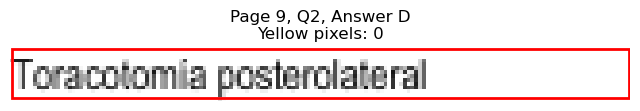


Page 9, Q2 - Selected Answer: A (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=136.5, y1=240.9
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 355
Page 9, Q3, A: Yellow percentage: 0.0%


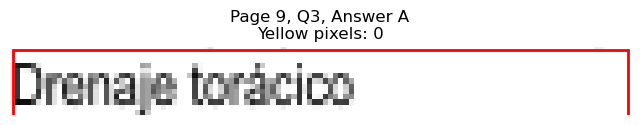

Page 9, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=160.1, y1=253.5
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 474
Page 9, Q3, B: Yellow percentage: 0.0%


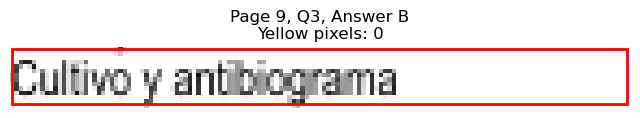

Page 9, Q3 - C: Detected box: x0=327.5, y0=228.3, x1=396.3, y1=240.9
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 474
Page 9, Q3, C: Yellow percentage: 0.0%


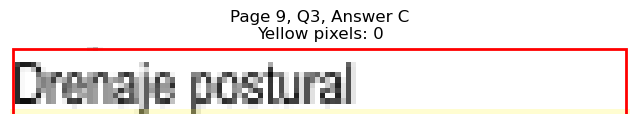

Page 9, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=377.3, y1=253.5
Page 9, Q3, D: Yellow pixels: 1142
Page 9, Q3, D: Total non-white pixels: 1414
Page 9, Q3, D: Yellow percentage: 80.8%


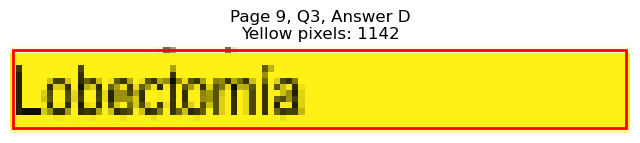


Page 9, Q3 - Selected Answer: D (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=173.7, y1=291.5
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 520
Page 9, Q4, A: Yellow percentage: 0.0%


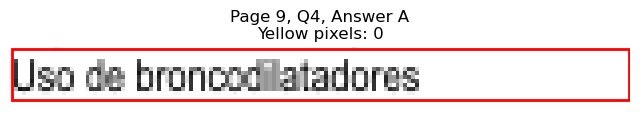

Page 9, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=145.0, y1=304.1
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 380
Page 9, Q4, B: Yellow percentage: 0.0%


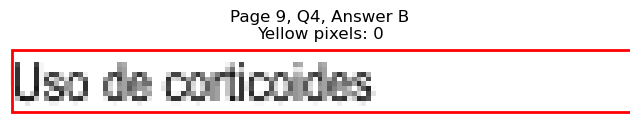

Page 9, Q4 - C: Detected box: x0=327.5, y0=278.8, x1=406.3, y1=291.5
Page 9, Q4, C: Yellow pixels: 130
Page 9, Q4, C: Total non-white pixels: 537
Page 9, Q4, C: Yellow percentage: 24.2%


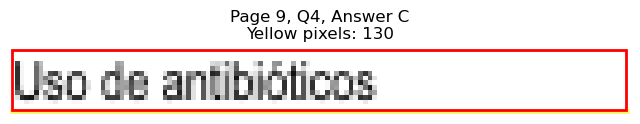

Page 9, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=414.8, y1=304.1
Page 9, Q4, D: Yellow pixels: 1438
Page 9, Q4, D: Total non-white pixels: 1932
Page 9, Q4, D: Yellow percentage: 74.4%


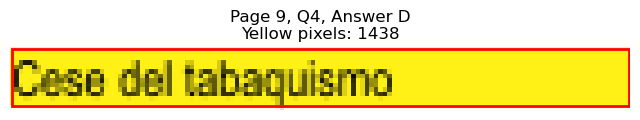


Page 9, Q4 - Selected Answer: D (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=329.2, x1=109.0, y1=341.9
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 204
Page 9, Q5, A: Yellow percentage: 0.0%


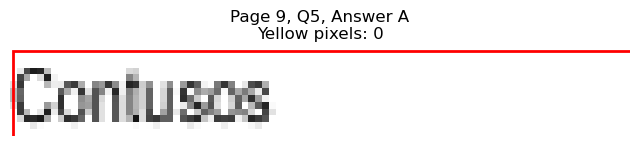

Page 9, Q5 - B: Detected box: x0=68.3, y0=341.9, x1=138.0, y1=354.6
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 365
Page 9, Q5, B: Yellow percentage: 0.0%


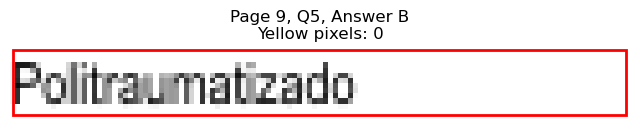

Page 9, Q5 - C: Detected box: x0=327.5, y0=329.2, x1=391.7, y1=341.9
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 337
Page 9, Q5, C: Yellow percentage: 0.0%


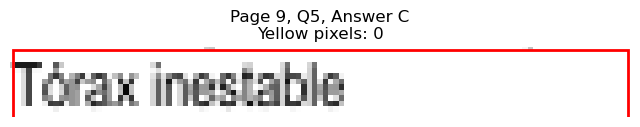

Page 9, Q5 - D: Detected box: x0=327.5, y0=341.9, x1=374.2, y1=354.6
Page 9, Q5, D: Yellow pixels: 1093
Page 9, Q5, D: Total non-white pixels: 1372
Page 9, Q5, D: Yellow percentage: 79.7%


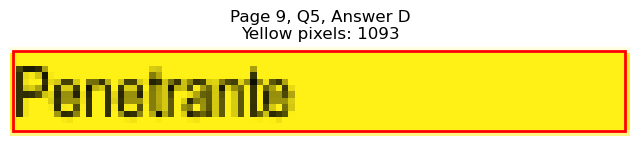


Page 9, Q5 - Selected Answer: D (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=404.9, x1=175.1, y1=417.6
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 564
Page 9, Q6, A: Yellow percentage: 0.0%


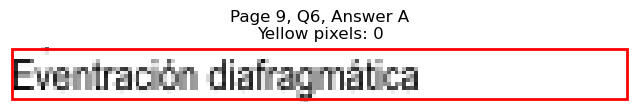

Page 9, Q6 - B: Detected box: x0=68.3, y0=417.6, x1=159.6, y1=430.3
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 448
Page 9, Q6, B: Yellow percentage: 0.0%


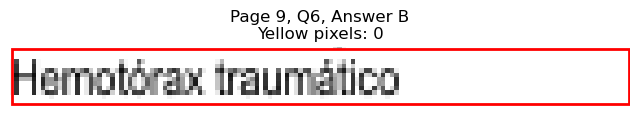

Page 9, Q6 - C: Detected box: x0=327.5, y0=404.9, x1=413.3, y1=417.6
Page 9, Q6, C: Yellow pixels: 1405
Page 9, Q6, C: Total non-white pixels: 1918
Page 9, Q6, C: Yellow percentage: 73.3%


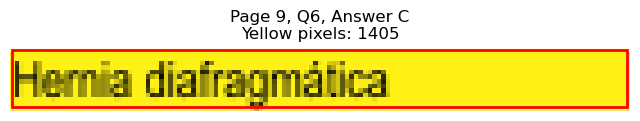

Page 9, Q6 - D: Detected box: x0=327.5, y0=417.6, x1=423.8, y1=430.3
Page 9, Q6, D: Yellow pixels: 146
Page 9, Q6, D: Total non-white pixels: 626
Page 9, Q6, D: Yellow percentage: 23.3%


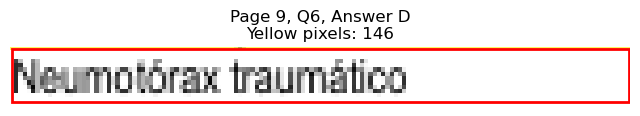


Page 9, Q6 - Selected Answer: C (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=468.1, x1=118.5, y1=480.7
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 256
Page 9, Q7, A: Yellow percentage: 0.0%


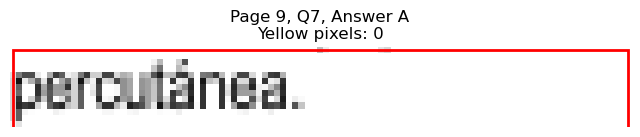

Page 9, Q7 - B: Detected box: x0=68.3, y0=480.8, x1=100.5, y1=493.4
Page 9, Q7, B: Yellow pixels: 879
Page 9, Q7, B: Total non-white pixels: 1162
Page 9, Q7, B: Yellow percentage: 75.6%


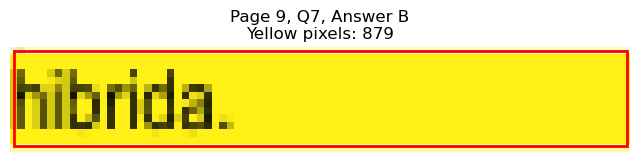

Page 9, Q7 - C: Detected box: x0=327.5, y0=468.1, x1=372.2, y1=480.7
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 211
Page 9, Q7, C: Yellow percentage: 0.0%


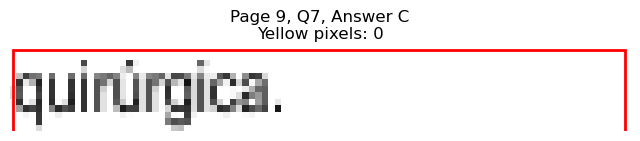

Page 9, Q7 - D: Detected box: x0=327.5, y0=480.8, x1=354.2, y1=493.4
Page 9, Q7, D: Yellow pixels: 0
Page 9, Q7, D: Total non-white pixels: 123
Page 9, Q7, D: Yellow percentage: 0.0%


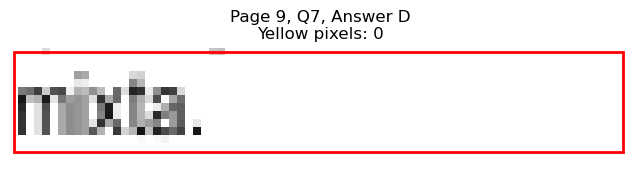


Page 9, Q7 - Selected Answer: B (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=531.2, x1=116.9, y1=543.8
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 232
Page 9, Q8, A: Yellow percentage: 0.0%


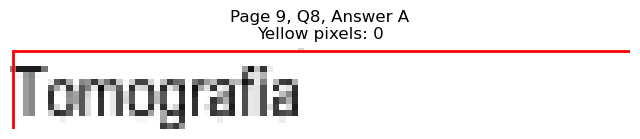

Page 9, Q8 - B: Detected box: x0=68.3, y0=543.8, x1=171.1, y1=556.4
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 550
Page 9, Q8, B: Yellow percentage: 0.0%


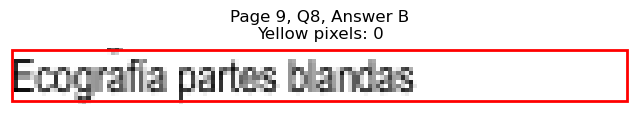

Page 9, Q8 - C: Detected box: x0=327.5, y0=531.2, x1=421.9, y1=543.8
Page 9, Q8, C: Yellow pixels: 1523
Page 9, Q8, C: Total non-white pixels: 1885
Page 9, Q8, C: Yellow percentage: 80.8%


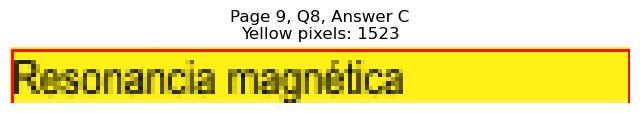

Page 9, Q8 - D: Detected box: x0=327.5, y0=543.8, x1=362.1, y1=556.4
Page 9, Q8, D: Yellow pixels: 82
Page 9, Q8, D: Total non-white pixels: 245
Page 9, Q8, D: Yellow percentage: 33.5%


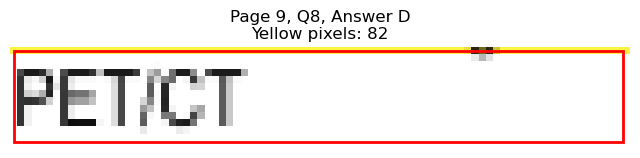


Page 9, Q8 - Selected Answer: C (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=68.3, y0=581.7, x1=178.6, y1=594.4
Page 9, Q9, A: Yellow pixels: 161
Page 9, Q9, A: Total non-white pixels: 745
Page 9, Q9, A: Yellow percentage: 21.6%


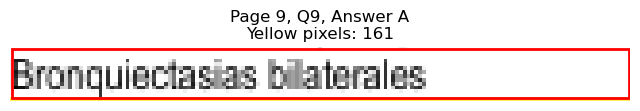

Page 9, Q9 - B: Detected box: x0=68.3, y0=594.3, x1=146.5, y1=607.0
Page 9, Q9, B: Yellow pixels: 1377
Page 9, Q9, B: Total non-white pixels: 1677
Page 9, Q9, B: Yellow percentage: 82.1%


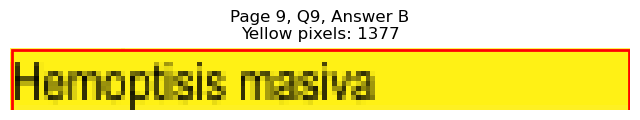

Page 9, Q9 - C: Detected box: x0=327.5, y0=581.7, x1=446.3, y1=594.4
Page 9, Q9, C: Yellow pixels: 0
Page 9, Q9, C: Total non-white pixels: 630
Page 9, Q9, C: Yellow percentage: 0.0%


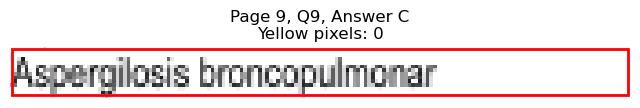

Page 9, Q9 - D: Detected box: x0=327.5, y0=594.3, x1=419.8, y1=607.0
Page 9, Q9, D: Yellow pixels: 0
Page 9, Q9, D: Total non-white pixels: 473
Page 9, Q9, D: Yellow percentage: 0.0%


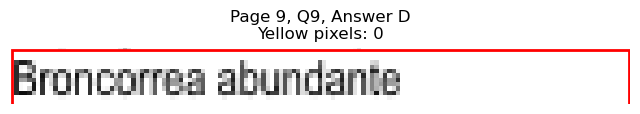


Page 9, Q9 - Selected Answer: B (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=68.3, y0=632.2, x1=109.5, y1=644.9
Page 9, Q10, A: Yellow pixels: 0
Page 9, Q10, A: Total non-white pixels: 311
Page 9, Q10, A: Yellow percentage: 0.0%


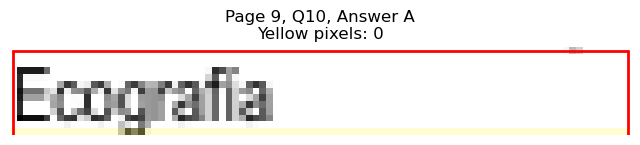

Page 9, Q10 - B: Detected box: x0=68.3, y0=644.9, x1=137.1, y1=657.5
Page 9, Q10, B: Yellow pixels: 1284
Page 9, Q10, B: Total non-white pixels: 1680
Page 9, Q10, B: Yellow percentage: 76.4%


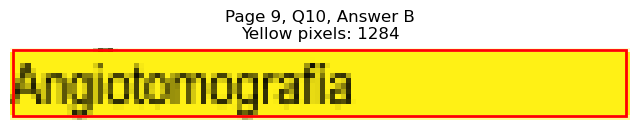

Page 9, Q10 - C: Detected box: x0=327.5, y0=632.2, x1=397.3, y1=644.9
Page 9, Q10, C: Yellow pixels: 0
Page 9, Q10, C: Total non-white pixels: 347
Page 9, Q10, C: Yellow percentage: 0.0%


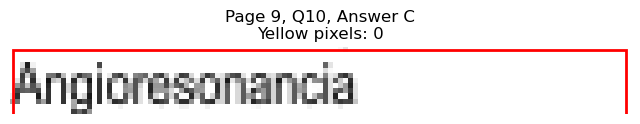

Page 9, Q10 - D: Detected box: x0=327.5, y0=543.8, x1=362.1, y1=556.4
Page 9, Q10, D: Yellow pixels: 82
Page 9, Q10, D: Total non-white pixels: 245
Page 9, Q10, D: Yellow percentage: 33.5%


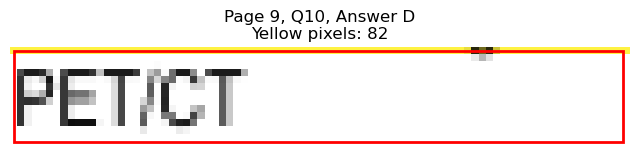


Page 9, Q10 - Selected Answer: B (based on yellow pixel count)




Page 9, Q11 - A: Detected box: x0=68.3, y0=682.7, x1=125.4, y1=695.3
Page 9, Q11, A: Yellow pixels: 0
Page 9, Q11, A: Total non-white pixels: 271
Page 9, Q11, A: Yellow percentage: 0.0%


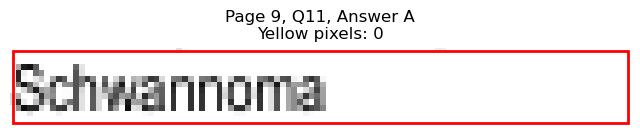

Page 9, Q11 - B: Detected box: x0=68.3, y0=695.4, x1=137.5, y1=708.0
Page 9, Q11, B: Yellow pixels: 1311
Page 9, Q11, B: Total non-white pixels: 1563
Page 9, Q11, B: Yellow percentage: 83.9%


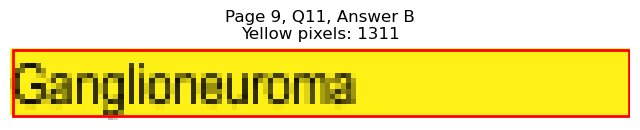

Page 9, Q11 - C: Detected box: x0=327.5, y0=682.7, x1=384.7, y1=695.3
Page 9, Q11, C: Yellow pixels: 0
Page 9, Q11, C: Total non-white pixels: 289
Page 9, Q11, C: Yellow percentage: 0.0%


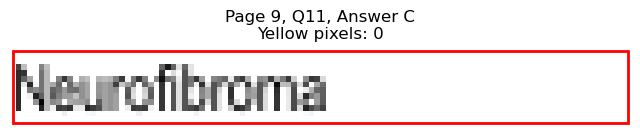

Page 9, Q11 - D: Detected box: x0=327.5, y0=695.4, x1=388.3, y1=708.0
Page 9, Q11, D: Yellow pixels: 0
Page 9, Q11, D: Total non-white pixels: 316
Page 9, Q11, D: Yellow percentage: 0.0%


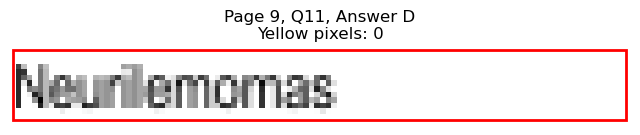


Page 9, Q11 - Selected Answer: B (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,"Varón de 44 años, hace 4 horas sufre traumatis..."
1,Recién nacido con cianosis y taquipnea. Rx tór...
2,"Niño de 5 años con insuficiencia cardiaca, des..."
3,"Varón de 42 años, que sufre una contusión en p..."
4,En TC. ¿Cuál es un signo indirecto de lesión a...
...,...
95,La revascularización quirúrgica de la DA con l...
96,Varón 18 años que refiere crecimiento progresi...
97,¿Cuál es la indicación principal del tratamien...
98,¿Cuál es el método diagnóstico de elección ant...


In [8]:
answers_df

,option_A,option_B,option_C,option_D
0,Inserción de catéter en 2do EICD en LMC,Rx de tórax PA y lateral derecha,Drenaje pleural derecho,Toracoscopía exploradora
1,Anomalía de Ebstein,Insuficiencia mitral congénita,Transposición de grandes vasos simple,Tetralogía de Fallot
2,Tetralogía de Fallot,Anomalía de Taussig-Bing,Atresia tricuspidea,Retorno venoso anómalo pulmonar total
3,Vendaje elástico en tórax,Analgésico y posición semisentado,Corsé elástico,Drenaje torácico
4,Extravasación del contraste,Hematoma periaórtico,Seudoaneurisma,Colgajo en la íntima
...,...,...,...,...
95,percutánea.,hibrida.,quirúrgica.,mixta.
96,Tomografía,Ecografía partes blandas,Resonancia magnética,PET/CT
97,Bronquiectasias bilaterales,Hemoptisis masiva,Aspergilosis broncopulmonar,Broncorrea abundante
98,Ecografía,Angiotomografía,Angioresonancia,PET/CT


In [9]:
correct_answers_df

,correct_answer
0,A
1,C
2,D
3,B
4,B
...,...
95,B
96,C
97,B
98,B


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,correct_answer
0,"Varón de 44 años, hace 4 horas sufre traumatis...",Inserción de catéter en 2do EICD en LMC,Rx de tórax PA y lateral derecha,Drenaje pleural derecho,Toracoscopía exploradora,A
1,Recién nacido con cianosis y taquipnea. Rx tór...,Anomalía de Ebstein,Insuficiencia mitral congénita,Transposición de grandes vasos simple,Tetralogía de Fallot,C
2,"Niño de 5 años con insuficiencia cardiaca, des...",Tetralogía de Fallot,Anomalía de Taussig-Bing,Atresia tricuspidea,Retorno venoso anómalo pulmonar total,D
3,"Varón de 42 años, que sufre una contusión en p...",Vendaje elástico en tórax,Analgésico y posición semisentado,Corsé elástico,Drenaje torácico,B
4,En TC. ¿Cuál es un signo indirecto de lesión a...,Extravasación del contraste,Hematoma periaórtico,Seudoaneurisma,Colgajo en la íntima,B
...,...,...,...,...,...,...
95,La revascularización quirúrgica de la DA con l...,percutánea.,hibrida.,quirúrgica.,mixta.,B
96,Varón 18 años que refiere crecimiento progresi...,Tomografía,Ecografía partes blandas,Resonancia magnética,PET/CT,C
97,¿Cuál es la indicación principal del tratamien...,Bronquiectasias bilaterales,Hemoptisis masiva,Aspergilosis broncopulmonar,Broncorrea abundante,B
98,¿Cuál es el método diagnóstico de elección ant...,Ecografía,Angiotomografía,Angioresonancia,PET/CT,B


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/CIRUGÍA DE TORÁX Y CARDIOVASCULAR.csv
